# ORIGINAL RUN 9 BARS

Loading data from: /lhome/ific/v/villamil/muonveto/NEW_muonveto/data/muons_20261028-100836.h5 ...
Loaded 813,551 events over 124.45 seconds.
Total DAQ Trigger Rate: 6537.1 Hz

Bar   | SiPM A/B   | True Ped A   | True Ped B   | Coinc Hits   | Rate (Hz)    | % of DAQ   | Status      
0     |  0, 1    | 216.0 (±23.7) | 227.0 (±14.8) | 958          | 7.7          | 0.1      % | OK (Cosmic) 
1     |  2, 3    | 216.0 (±23.7) | 209.0 (±25.0) | 3,252        | 26.1         | 0.4      % | OK (Cosmic) 
2     |  4, 5    | 195.0 (±25.0) | 204.0 (±25.0) | 10,733       | 86.2         | 1.3      % | OK (Cosmic) 
3     |  6, 7    | 212.0 (±25.0) | 207.0 (±25.0) | 214,921      | 1726.9       | 26.4     % | SINGING! ⚠️ 
4     |  8, 9    | 223.0 (±22.2) | 200.0 (±14.8) | 2,509        | 20.2         | 0.3      % | OK (Cosmic) 
5     | 10, 11   | 203.0 (±14.8) | 205.0 (±14.8) | 2,530        | 20.3         | 0.3      % | OK (Cosmic) 
6     | 12, 13   | 219.0 (±13.3) | 200.0 (±13.3) | 1,515        | 12.2     

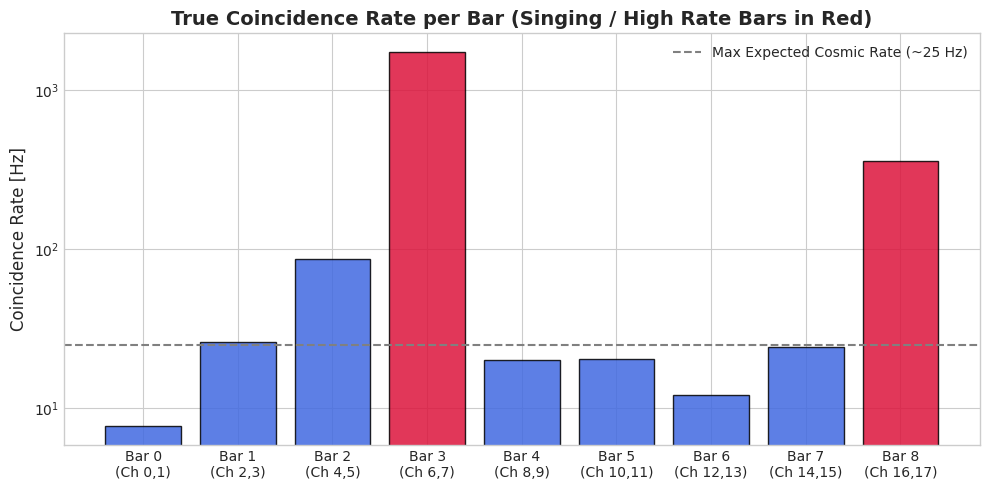

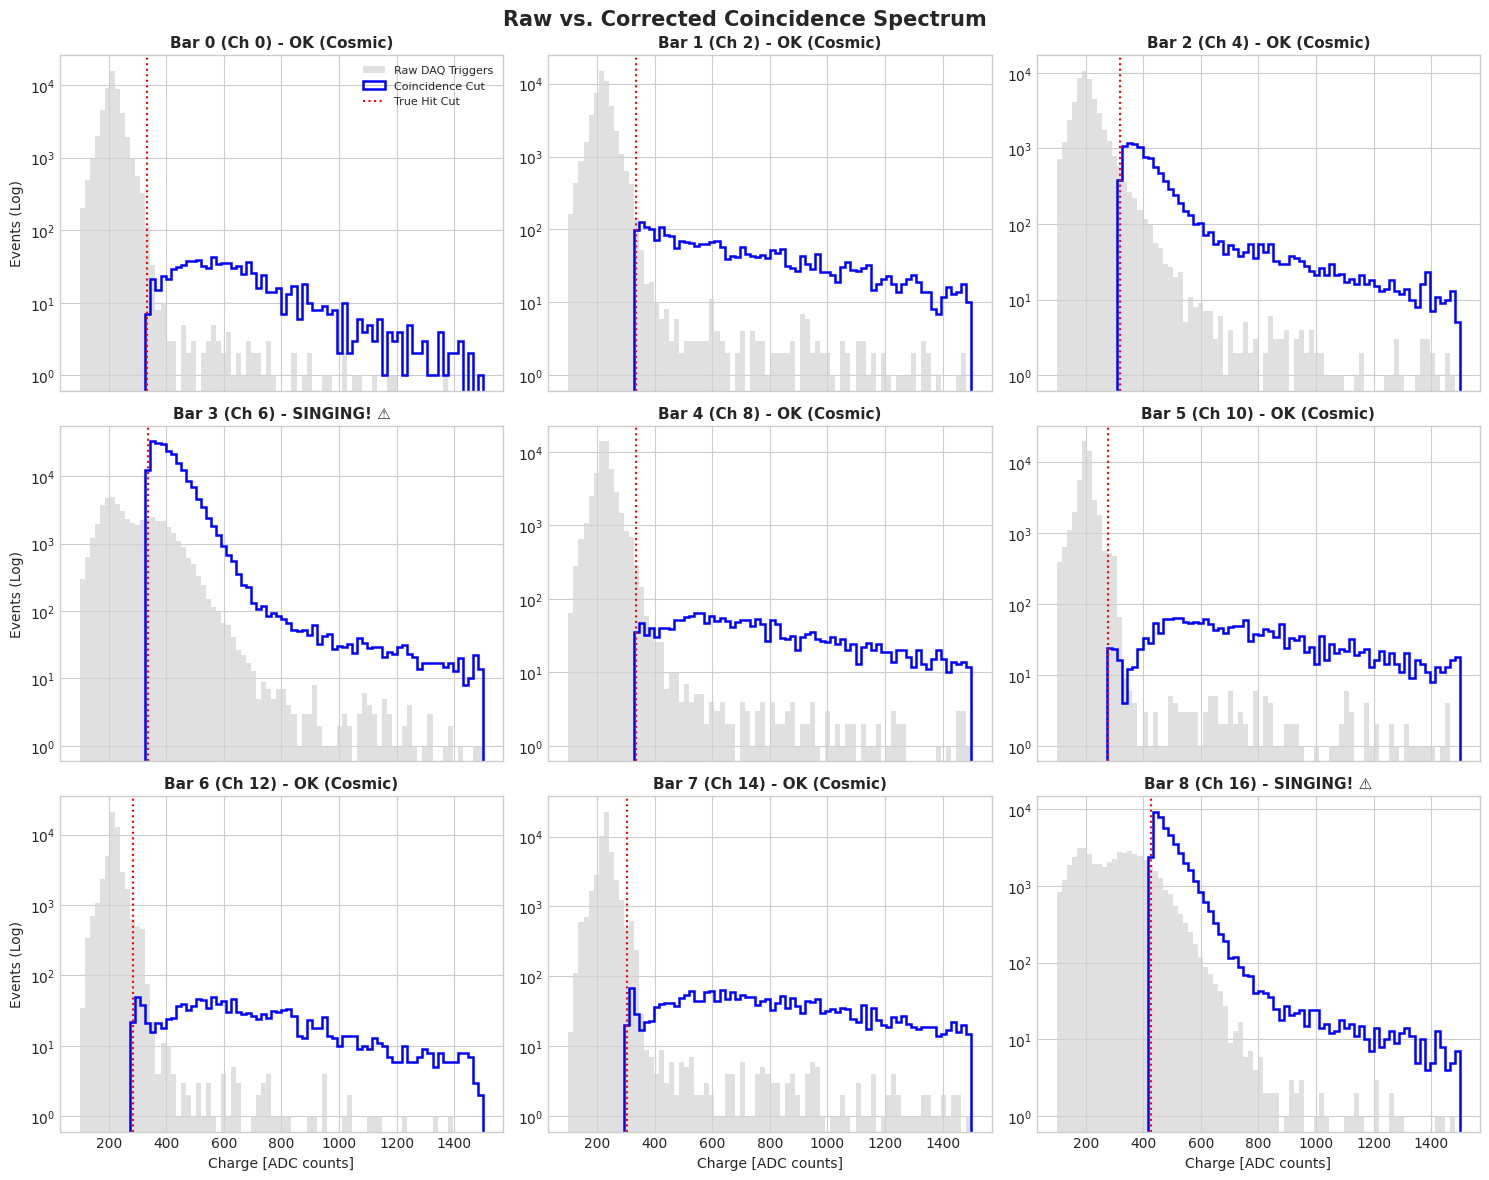

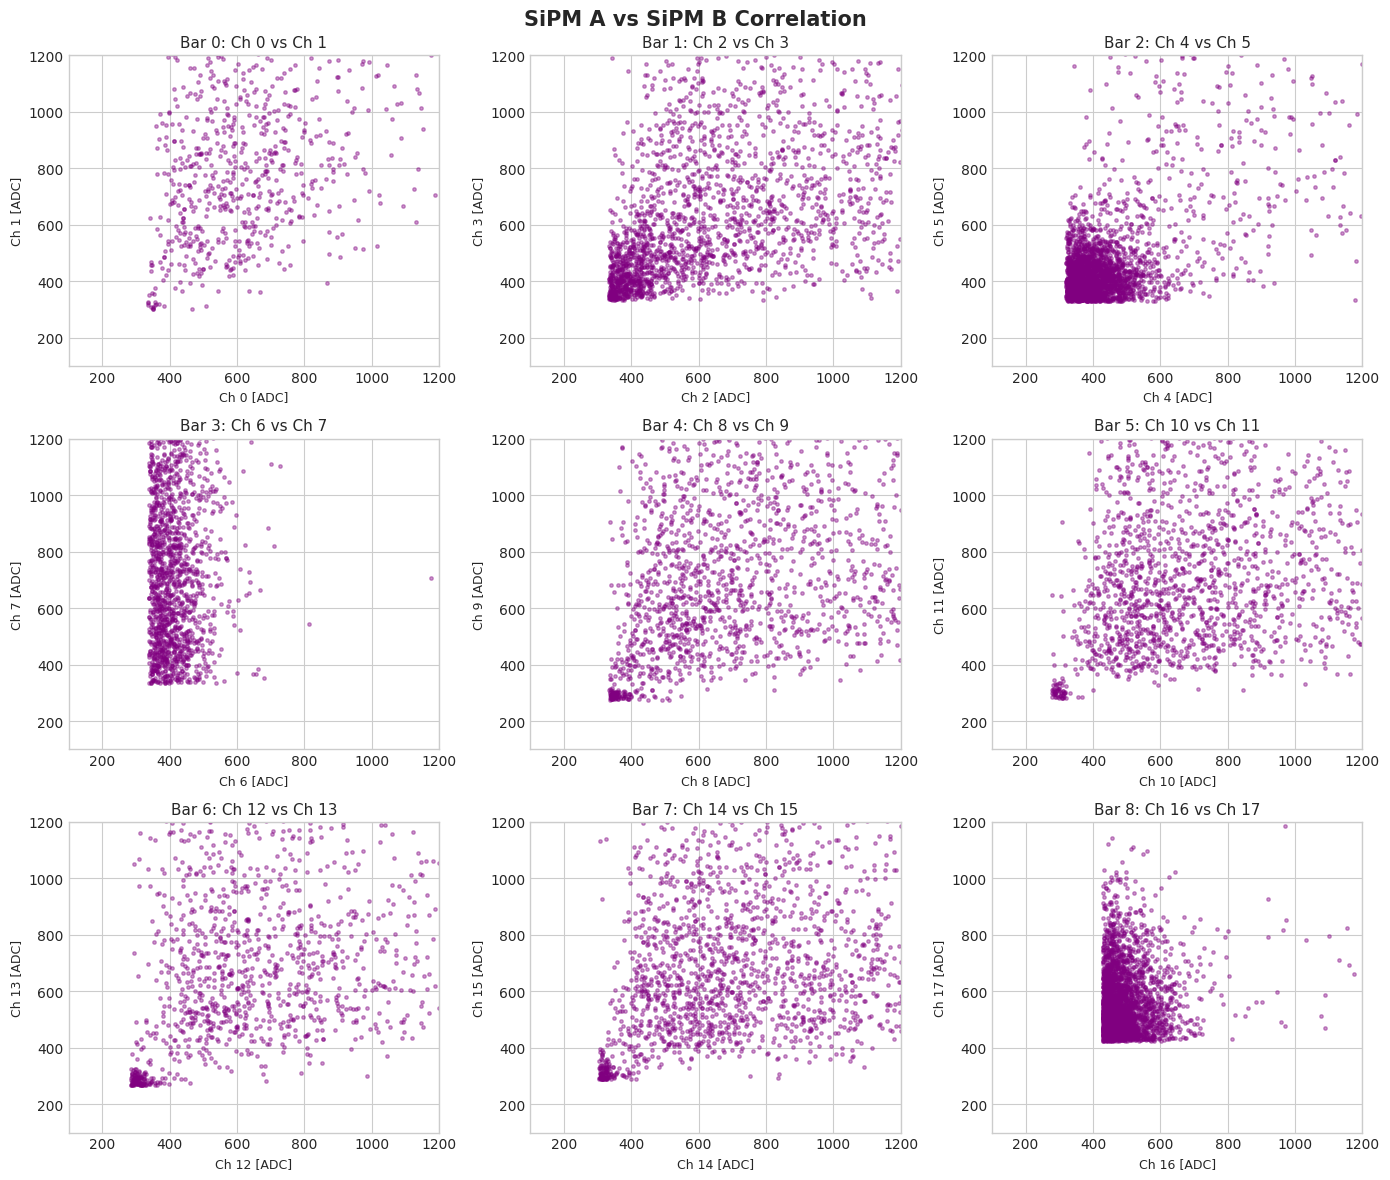

In [ ]:
import sys
import numpy as np
import matplotlib.pyplot as plt

try:
    import hdf5plugin
    import h5py
    READER = "h5py"
except ImportError:
    try:
        import tables
        READER = "tables"
    except ImportError:
        print("[-] Please run: pip install hdf5plugin")
        sys.exit(1)

# ==============================================================================
# CONFIGURATION
# ==============================================================================
FILE_PATH = "/lhome/ific/v/villamil/muonveto/NEW_muonveto/data/muons_2.h5"  # <-- Replace with your file name

BAR_MAP = {
    0: (0, 1),
    1: (2, 3),
    2: (4, 5),
    3: (6, 7),
    4: (8, 9),
    5: (10, 11),
    6: (12, 13),
    7: (14, 15),
    8: (16, 17)
}

# ==============================================================================
# DATA LOADING
# ==============================================================================
print(f"Loading data from: {FILE_PATH} ...")
if READER == "h5py":
    with h5py.File(FILE_PATH, 'r') as f:
        charges = np.array(f['charges'])
        events = np.array(f['events'])
else:
    with tables.open_file(FILE_PATH, 'r') as f:
        charges = f.root.charges.read()
        events = f.root.events.read()

n_events, n_channels = charges.shape
timestamps = events['timestamp']
time_diff = timestamps[-1] - timestamps[0]
elapsed_time_s = (time_diff / 1e9) if time_diff > 1e11 else (time_diff / 1000.0 if time_diff > 0 else 1.0)

print(f"Loaded {n_events:,} events over {elapsed_time_s:.2f} seconds.")
print(f"Total DAQ Trigger Rate: {n_events / elapsed_time_s:.1f} Hz\n")

# ==============================================================================
# ROBUST PHYSICAL PEDESTAL & NOISE DETERMINATION
# ==============================================================================
# To find the true electronic baseline even on singing channels,
# we find the mode (most common value) in the raw ADC baseline window [150, 260].
pedestals = np.zeros(n_channels)
ped_rms = np.zeros(n_channels)
thresholds = np.zeros(n_channels)

for ch in range(n_channels):
    ch_data = charges[:100000, ch]
    # Histogram in true electronic baseline window
    counts, bin_edges = np.histogram(ch_data, bins=110, range=(150, 260))
    mode_ped = bin_edges[np.argmax(counts)]
    
    # If a channel has no peak in that window (severely shifted), fall back to median
    if mode_ped <= 152 or mode_ped >= 258:
        mode_ped = np.median(ch_data)
        
    pedestals[ch] = mode_ped
    
    # Typical electronic baseline noise for this CAEN board is ~15-20 ADC counts.
    # Cap RMS to prevent singing bars from blowing up their own threshold!
    mad = np.median(np.abs(ch_data - mode_ped))
    sigma = min(1.4826 * mad, 25.0)  # capped at 25 ADC counts
    ped_rms[ch] = max(sigma, 12.0)
    
    # Threshold: Pedestal + 5*sigma (approx 60-70 ADC counts above baseline)
    thresholds[ch] = pedestals[ch] + max(5.0 * ped_rms[ch], 50.0)

# ==============================================================================
# COINCIDENCE SEARCH & TRIGGER ATTRIBUTION
# ==============================================================================
bar_stats = {}

print("=" * 102)
print(f"{'Bar':<5} | {'SiPM A/B':<10} | {'True Ped A':<12} | {'True Ped B':<12} | {'Coinc Hits':<12} | {'Rate (Hz)':<12} | {'% of DAQ':<10} | {'Status':<12}")
print("=" * 102)

for bar_id, (ch_a, ch_b) in BAR_MAP.items():
    q_a = charges[:, ch_a]
    q_b = charges[:, ch_b]
    
    # Coincidence condition: Both SiPMs exceed true baseline threshold
    coincidence_mask = (q_a > thresholds[ch_a]) & (q_b > thresholds[ch_b])
    n_hits = int(np.sum(coincidence_mask))
    rate_hz = n_hits / elapsed_time_s
    pct_daq = (n_hits / n_events) * 100.0
    
    if rate_hz > 100.0:
        status = "SINGING! ⚠️"
    elif rate_hz < 1.0:
        status = "Very Low / Deaf"
    else:
        status = "OK (Cosmic)"
        
    bar_stats[bar_id] = {
        'ch_a': ch_a, 'ch_b': ch_b,
        'hits': n_hits, 'rate': rate_hz, 'pct': pct_daq,
        'mask': coincidence_mask,
        'q_a': q_a, 'q_b': q_b,
        'status': status
    }
    
    ped_a_str = f"{pedestals[ch_a]:.1f} (±{ped_rms[ch_a]:.1f})"
    ped_b_str = f"{pedestals[ch_b]:.1f} (±{ped_rms[ch_b]:.1f})"
    print(f"{bar_id:<5} | {ch_a:>2}, {ch_b:<2}   | {ped_a_str:<12} | {ped_b_str:<12} | {n_hits:<12,d} | {rate_hz:<12.1f} | {pct_daq:<9.1f}% | {status:<12}")

print("=" * 102 + "\n")

# ==============================================================================
# PLOTTING DIAGNOSTICS
# ==============================================================================
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# 1. Bar Chart: Trigger Rates
fig, ax = plt.subplots(figsize=(10, 5))
bars = list(bar_stats.keys())
rates = [bar_stats[b]['rate'] for b in bars]
colors = ['crimson' if bar_stats[b]['rate'] > 100 else 'royalblue' for b in bars]

ax.bar([f"Bar {b}\n(Ch {bar_stats[b]['ch_a']},{bar_stats[b]['ch_b']})" for b in bars], 
       rates, color=colors, edgecolor='black', alpha=0.85)
ax.set_ylabel("Coincidence Rate [Hz]", fontsize=12)
ax.set_title("True Coincidence Rate per Bar (Singing / High Rate Bars in Red)", fontsize=14, fontweight='bold')
ax.axhline(25, color='gray', linestyle='--', label='Max Expected Cosmic Rate (~25 Hz)')
ax.set_yscale('log')
ax.legend(fontsize=10)
plt.tight_layout()
plt.savefig("/lhome/ific/v/villamil/muonveto/NEW_muonveto/veto_rates_summary_v2.png", dpi=200)

# 2. Recovered Cosmic Muon Spectra
fig, axes = plt.subplots(3, 3, figsize=(15, 12), sharex=True)
axes = axes.flatten()

for b in bars:
    ax = axes[b]
    ch_a = bar_stats[b]['ch_a']
    q_a = bar_stats[b]['q_a']
    coinc_mask = bar_stats[b]['mask']
    
    plot_q = q_a if len(q_a) <= 50000 else np.random.choice(q_a, 50000, replace=False)
    ax.hist(plot_q, bins=80, range=(100, 1500), color='lightgray', label='Raw DAQ Triggers', alpha=0.7)
    
    if np.sum(coinc_mask) > 0:
        ax.hist(q_a[coinc_mask], bins=80, range=(100, 1500), color='blue', histtype='step', linewidth=1.8, label='Coincidence Cut')
        
    ax.axvline(thresholds[ch_a], color='red', linestyle=':', label='True Hit Cut')
    ax.set_title(f"Bar {b} (Ch {ch_a}) - {bar_stats[b]['status']}", fontsize=11, fontweight='bold')
    ax.set_yscale('log')
    if b >= 6:
        ax.set_xlabel("Charge [ADC counts]", fontsize=10)
    if b % 3 == 0:
        ax.set_ylabel("Events (Log)", fontsize=10)
    if b == 0:
        ax.legend(fontsize=8, loc='upper right')

plt.suptitle("Raw vs. Corrected Coincidence Spectrum", fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig("/lhome/ific/v/villamil/muonveto/NEW_muonveto/veto_signals_recovered_v2.png", dpi=200)

# 3. SiPM A vs SiPM B Correlation
fig, axes = plt.subplots(3, 3, figsize=(14, 12))
axes = axes.flatten()

for b in bars:
    ax = axes[b]
    ch_a = bar_stats[b]['ch_a']
    ch_b = bar_stats[b]['ch_b']
    q_a = bar_stats[b]['q_a']
    q_b = bar_stats[b]['q_b']
    coinc_mask = bar_stats[b]['mask']
    
    if np.sum(coinc_mask) > 5:
        idx = np.where(coinc_mask)[0]
        if len(idx) > 3000:
            idx = np.random.choice(idx, 3000, replace=False)
        ax.scatter(q_a[idx], q_b[idx], color='purple', s=6, alpha=0.4)
    else:
        ax.text(0.5, 0.5, 'Insufficient Hits', ha='center', va='center', transform=ax.transAxes, color='gray')
        
    ax.set_title(f"Bar {b}: Ch {ch_a} vs Ch {ch_b}", fontsize=11)
    ax.set_xlim(100, 1200)
    ax.set_ylim(100, 1200)
    ax.set_xlabel(f"Ch {ch_a} [ADC]", fontsize=9)
    ax.set_ylabel(f"Ch {ch_b} [ADC]", fontsize=9)

plt.suptitle("SiPM A vs SiPM B Correlation", fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig("/lhome/ific/v/villamil/muonveto/NEW_muonveto/veto_sipm_correlations_v2.png", dpi=200)
print("[+] Analysis completed and plots saved (v2).")

# First try reducing BIAS

Loading data from: /lhome/ific/v/villamil/muonveto/NEW_muonveto/data/muons_20261028-114520.h5 ...
Loaded 315,951 events over 250.95 seconds.
Total DAQ Trigger Rate: 1259.0 Hz

Bar   | SiPM A/B   | True Ped A   | True Ped B   | Coinc Hits   | Rate (Hz)    | % of DAQ   | Status      
0     |  0, 1    | 210.0 (±25.0) | 225.0 (±13.3) | 2,306        | 9.2          | 0.7      % | OK (Cosmic) 
1     |  2, 3    | 220.0 (±25.0) | 211.0 (±25.0) | 7,649        | 30.5         | 2.4      % | OK (Cosmic) 
2     |  4, 5    | 196.0 (±25.0) | 205.0 (±25.0) | 32,671       | 130.2        | 10.3     % | SINGING! ⚠️ 
3     |  6, 7    | 322.0 (±25.0) | 204.0 (±25.0) | 18,477       | 73.6         | 5.8      % | OK (Cosmic) 
4     |  8, 9    | 223.0 (±23.7) | 198.0 (±13.3) | 5,848        | 23.3         | 1.9      % | OK (Cosmic) 
5     | 10, 11   | 200.0 (±13.3) | 205.0 (±12.0) | 6,036        | 24.1         | 1.9      % | OK (Cosmic) 
6     | 12, 13   | 218.0 (±12.0) | 197.0 (±12.0) | 3,370        | 13.4     

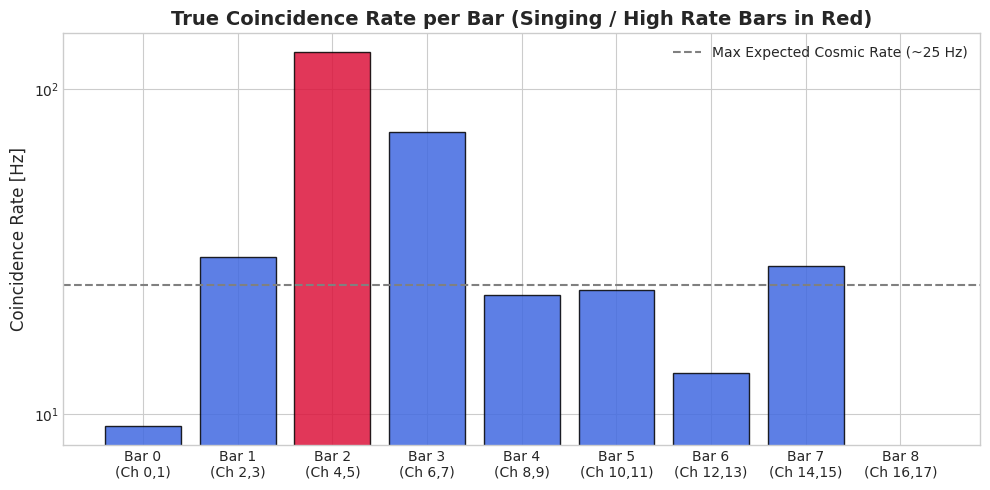

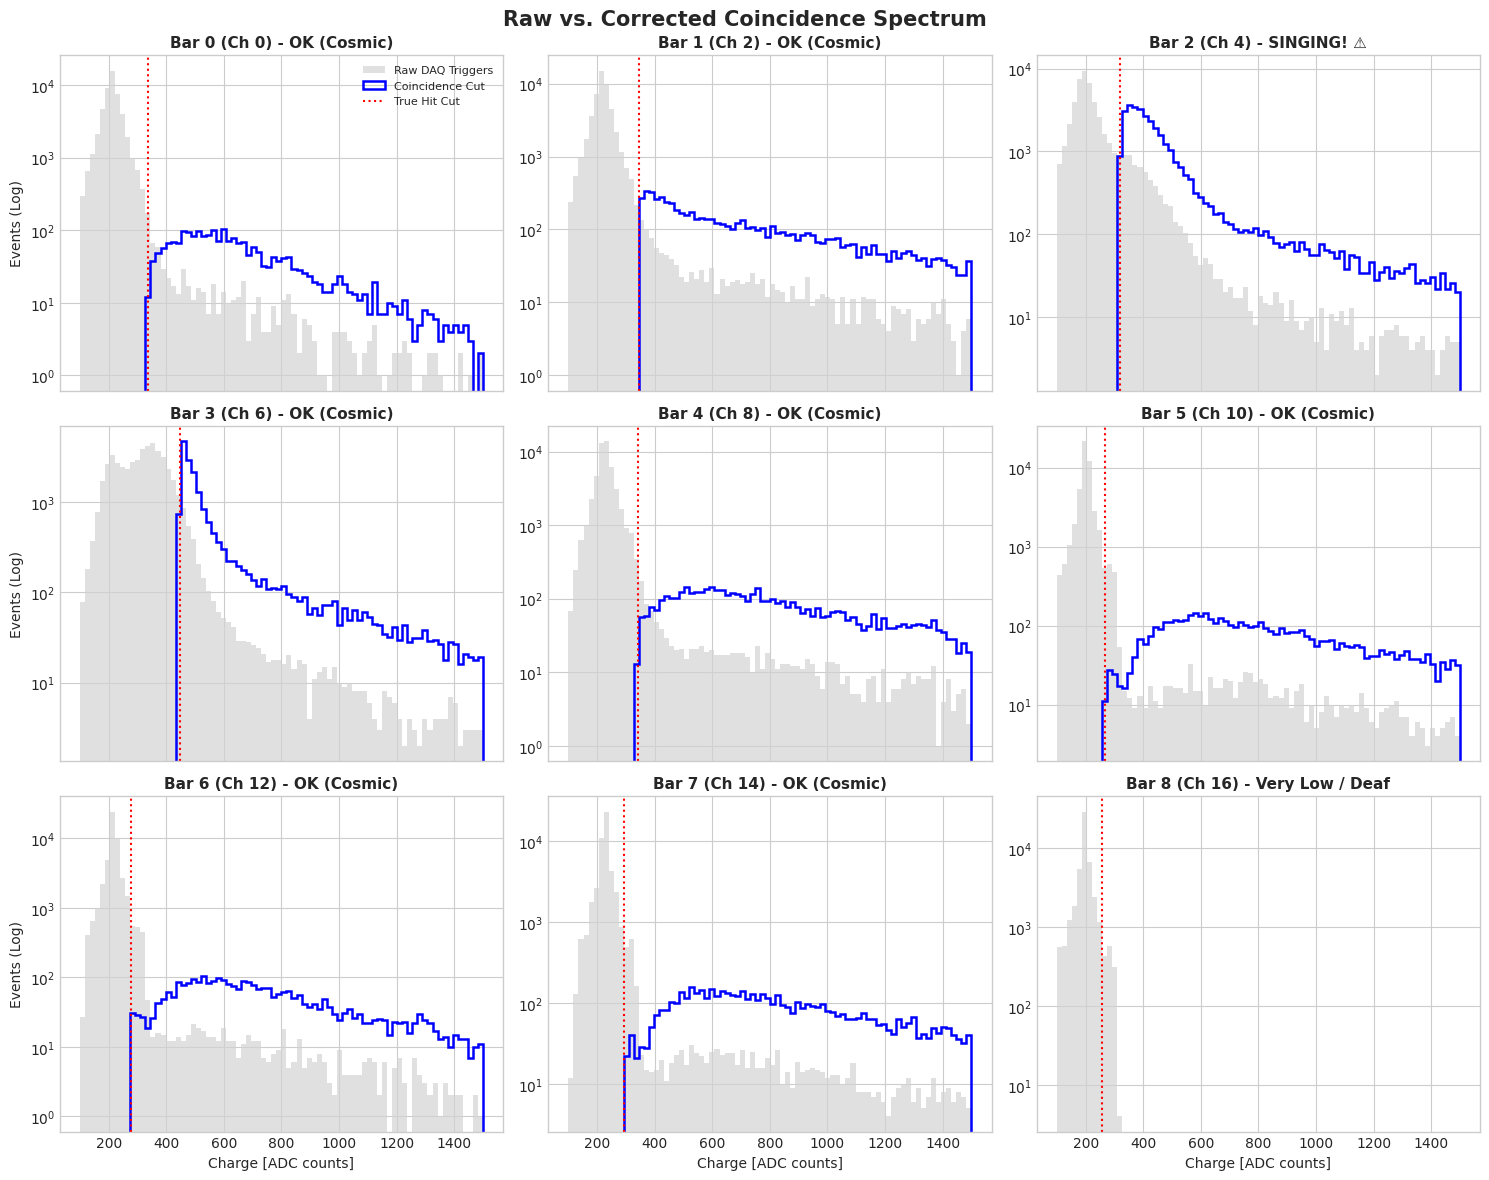

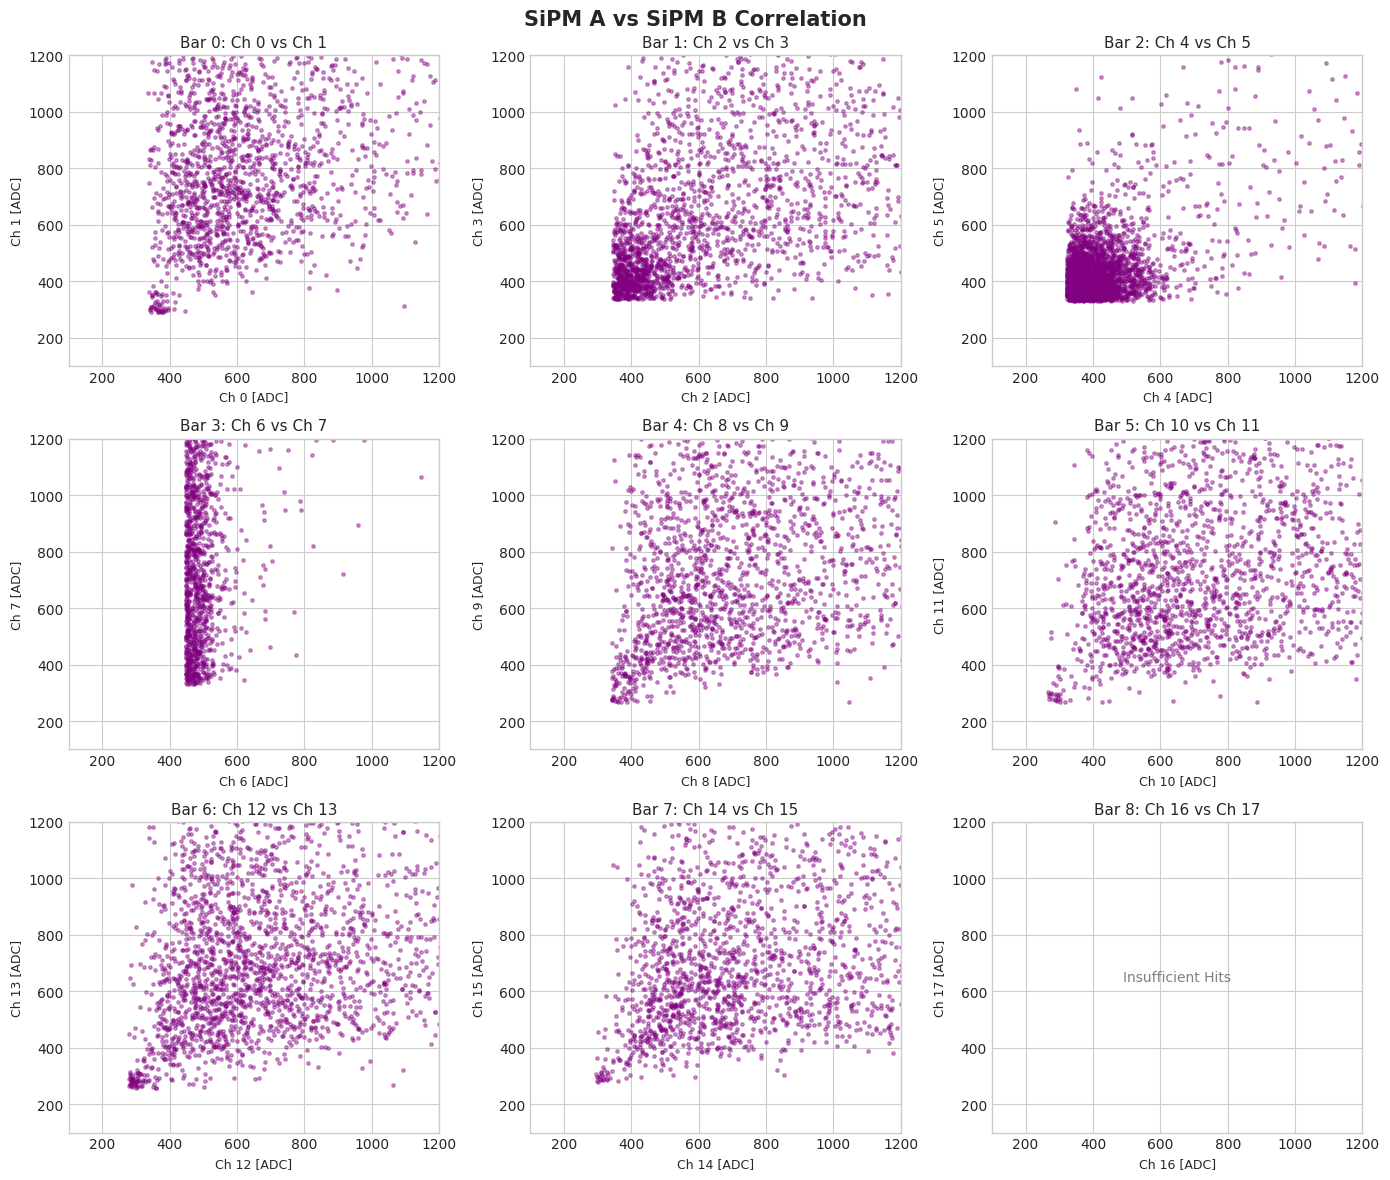

In [ ]:
import sys
import numpy as np
import matplotlib.pyplot as plt

try:
    import hdf5plugin
    import h5py
    READER = "h5py"
except ImportError:
    try:
        import tables
        READER = "tables"
    except ImportError:
        print("[-] Please run: pip install hdf5plugin")
        sys.exit(1)

# ==============================================================================
# CONFIGURATION
# ==============================================================================
FILE_PATH = "/lhome/ific/v/villamil/muonveto/NEW_muonveto/data/muons_3.h5"  # <-- Replace with your file name

BAR_MAP = {
    0: (0, 1),
    1: (2, 3),
    2: (4, 5),
    3: (6, 7),
    4: (8, 9),
    5: (10, 11),
    6: (12, 13),
    7: (14, 15),
    8: (16, 17)
}

# ==============================================================================
# DATA LOADING
# ==============================================================================
print(f"Loading data from: {FILE_PATH} ...")
if READER == "h5py":
    with h5py.File(FILE_PATH, 'r') as f:
        charges = np.array(f['charges'])
        events = np.array(f['events'])
else:
    with tables.open_file(FILE_PATH, 'r') as f:
        charges = f.root.charges.read()
        events = f.root.events.read()

n_events, n_channels = charges.shape
timestamps = events['timestamp']
time_diff = timestamps[-1] - timestamps[0]
elapsed_time_s = (time_diff / 1e9) if time_diff > 1e11 else (time_diff / 1000.0 if time_diff > 0 else 1.0)

print(f"Loaded {n_events:,} events over {elapsed_time_s:.2f} seconds.")
print(f"Total DAQ Trigger Rate: {n_events / elapsed_time_s:.1f} Hz\n")

# ==============================================================================
# ROBUST PHYSICAL PEDESTAL & NOISE DETERMINATION
# ==============================================================================
# To find the true electronic baseline even on singing channels,
# we find the mode (most common value) in the raw ADC baseline window [150, 260].
pedestals = np.zeros(n_channels)
ped_rms = np.zeros(n_channels)
thresholds = np.zeros(n_channels)

for ch in range(n_channels):
    ch_data = charges[:100000, ch]
    # Histogram in true electronic baseline window
    counts, bin_edges = np.histogram(ch_data, bins=110, range=(150, 260))
    mode_ped = bin_edges[np.argmax(counts)]
    
    # If a channel has no peak in that window (severely shifted), fall back to median
    if mode_ped <= 152 or mode_ped >= 258:
        mode_ped = np.median(ch_data)
        
    pedestals[ch] = mode_ped
    
    # Typical electronic baseline noise for this CAEN board is ~15-20 ADC counts.
    # Cap RMS to prevent singing bars from blowing up their own threshold!
    mad = np.median(np.abs(ch_data - mode_ped))
    sigma = min(1.4826 * mad, 25.0)  # capped at 25 ADC counts
    ped_rms[ch] = max(sigma, 12.0)
    
    # Threshold: Pedestal + 5*sigma (approx 60-70 ADC counts above baseline)
    thresholds[ch] = pedestals[ch] + max(5.0 * ped_rms[ch], 50.0)

# ==============================================================================
# COINCIDENCE SEARCH & TRIGGER ATTRIBUTION
# ==============================================================================
bar_stats = {}

print("=" * 102)
print(f"{'Bar':<5} | {'SiPM A/B':<10} | {'True Ped A':<12} | {'True Ped B':<12} | {'Coinc Hits':<12} | {'Rate (Hz)':<12} | {'% of DAQ':<10} | {'Status':<12}")
print("=" * 102)

for bar_id, (ch_a, ch_b) in BAR_MAP.items():
    q_a = charges[:, ch_a]
    q_b = charges[:, ch_b]
    
    # Coincidence condition: Both SiPMs exceed true baseline threshold
    coincidence_mask = (q_a > thresholds[ch_a]) & (q_b > thresholds[ch_b])
    n_hits = int(np.sum(coincidence_mask))
    rate_hz = n_hits / elapsed_time_s
    pct_daq = (n_hits / n_events) * 100.0
    
    if rate_hz > 100.0:
        status = "SINGING! ⚠️"
    elif rate_hz < 1.0:
        status = "Very Low / Deaf"
    else:
        status = "OK (Cosmic)"
        
    bar_stats[bar_id] = {
        'ch_a': ch_a, 'ch_b': ch_b,
        'hits': n_hits, 'rate': rate_hz, 'pct': pct_daq,
        'mask': coincidence_mask,
        'q_a': q_a, 'q_b': q_b,
        'status': status
    }
    
    ped_a_str = f"{pedestals[ch_a]:.1f} (±{ped_rms[ch_a]:.1f})"
    ped_b_str = f"{pedestals[ch_b]:.1f} (±{ped_rms[ch_b]:.1f})"
    print(f"{bar_id:<5} | {ch_a:>2}, {ch_b:<2}   | {ped_a_str:<12} | {ped_b_str:<12} | {n_hits:<12,d} | {rate_hz:<12.1f} | {pct_daq:<9.1f}% | {status:<12}")

print("=" * 102 + "\n")

# ==============================================================================
# PLOTTING DIAGNOSTICS
# ==============================================================================
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# 1. Bar Chart: Trigger Rates
fig, ax = plt.subplots(figsize=(10, 5))
bars = list(bar_stats.keys())
rates = [bar_stats[b]['rate'] for b in bars]
colors = ['crimson' if bar_stats[b]['rate'] > 100 else 'royalblue' for b in bars]

ax.bar([f"Bar {b}\n(Ch {bar_stats[b]['ch_a']},{bar_stats[b]['ch_b']})" for b in bars], 
       rates, color=colors, edgecolor='black', alpha=0.85)
ax.set_ylabel("Coincidence Rate [Hz]", fontsize=12)
ax.set_title("True Coincidence Rate per Bar (Singing / High Rate Bars in Red)", fontsize=14, fontweight='bold')
ax.axhline(25, color='gray', linestyle='--', label='Max Expected Cosmic Rate (~25 Hz)')
ax.set_yscale('log')
ax.legend(fontsize=10)
plt.tight_layout()
plt.savefig("/lhome/ific/v/villamil/muonveto/NEW_muonveto/veto_rates_summary_v2.png", dpi=200)

# 2. Recovered Cosmic Muon Spectra
fig, axes = plt.subplots(3, 3, figsize=(15, 12), sharex=True)
axes = axes.flatten()

for b in bars:
    ax = axes[b]
    ch_a = bar_stats[b]['ch_a']
    q_a = bar_stats[b]['q_a']
    coinc_mask = bar_stats[b]['mask']
    
    plot_q = q_a if len(q_a) <= 50000 else np.random.choice(q_a, 50000, replace=False)
    ax.hist(plot_q, bins=80, range=(100, 1500), color='lightgray', label='Raw DAQ Triggers', alpha=0.7)
    
    if np.sum(coinc_mask) > 0:
        ax.hist(q_a[coinc_mask], bins=80, range=(100, 1500), color='blue', histtype='step', linewidth=1.8, label='Coincidence Cut')
        
    ax.axvline(thresholds[ch_a], color='red', linestyle=':', label='True Hit Cut')
    ax.set_title(f"Bar {b} (Ch {ch_a}) - {bar_stats[b]['status']}", fontsize=11, fontweight='bold')
    ax.set_yscale('log')
    if b >= 6:
        ax.set_xlabel("Charge [ADC counts]", fontsize=10)
    if b % 3 == 0:
        ax.set_ylabel("Events (Log)", fontsize=10)
    if b == 0:
        ax.legend(fontsize=8, loc='upper right')

plt.suptitle("Raw vs. Corrected Coincidence Spectrum", fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig("/lhome/ific/v/villamil/muonveto/NEW_muonveto/veto_signals_recovered_v2.png", dpi=200)

# 3. SiPM A vs SiPM B Correlation
fig, axes = plt.subplots(3, 3, figsize=(14, 12))
axes = axes.flatten()

for b in bars:
    ax = axes[b]
    ch_a = bar_stats[b]['ch_a']
    ch_b = bar_stats[b]['ch_b']
    q_a = bar_stats[b]['q_a']
    q_b = bar_stats[b]['q_b']
    coinc_mask = bar_stats[b]['mask']
    
    if np.sum(coinc_mask) > 5:
        idx = np.where(coinc_mask)[0]
        if len(idx) > 3000:
            idx = np.random.choice(idx, 3000, replace=False)
        ax.scatter(q_a[idx], q_b[idx], color='purple', s=6, alpha=0.4)
    else:
        ax.text(0.5, 0.5, 'Insufficient Hits', ha='center', va='center', transform=ax.transAxes, color='gray')
        
    ax.set_title(f"Bar {b}: Ch {ch_a} vs Ch {ch_b}", fontsize=11)
    ax.set_xlim(100, 1200)
    ax.set_ylim(100, 1200)
    ax.set_xlabel(f"Ch {ch_a} [ADC]", fontsize=9)
    ax.set_ylabel(f"Ch {ch_b} [ADC]", fontsize=9)

plt.suptitle("SiPM A vs SiPM B Correlation", fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig("/lhome/ific/v/villamil/muonveto/NEW_muonveto/veto_sipm_correlations_v2.png", dpi=200)
print("[+] Analysis completed and plots saved (v2).")

# Second try reducing BIAS

Loading data from: /lhome/ific/v/villamil/muonveto/NEW_muonveto/data/muons_4.h5 ...
Loaded 60,111 events over 29.95 seconds.
Total DAQ Trigger Rate: 2007.0 Hz

Bar   | SiPM A/B   | Ped A      | Ped B      | Coinc Hits  | Rate (Hz)  | Saturated  | Status      
0     |  0, 1    | 211.0      | 223.0      | 240         | 8.0        | 0.83     % | OK (Cosmic) 
1     |  2, 3    | 219.0      | 205.0      | 910         | 30.4       | 1.10     % | OK (Cosmic) 
2     |  4, 5    | 197.0      | 202.0      | 1,991       | 66.5       | 0.20     % | SINGING! ⚠️ 
3     |  6, 7    | 319.0      | 205.0      | 3,922       | 130.9      | 11.70    % | SINGING! ⚠️ 
4     |  8, 9    | 221.0      | 198.0      | 680         | 22.7       | 0.44     % | OK (Cosmic) 
5     | 10, 11   | 200.0      | 205.0      | 736         | 24.6       | 1.36     % | OK (Cosmic) 
6     | 12, 13   | 219.0      | 196.0      | 403         | 13.5       | 0.74     % | OK (Cosmic) 
7     | 14, 15   | 227.0      | 212.0      | 858      

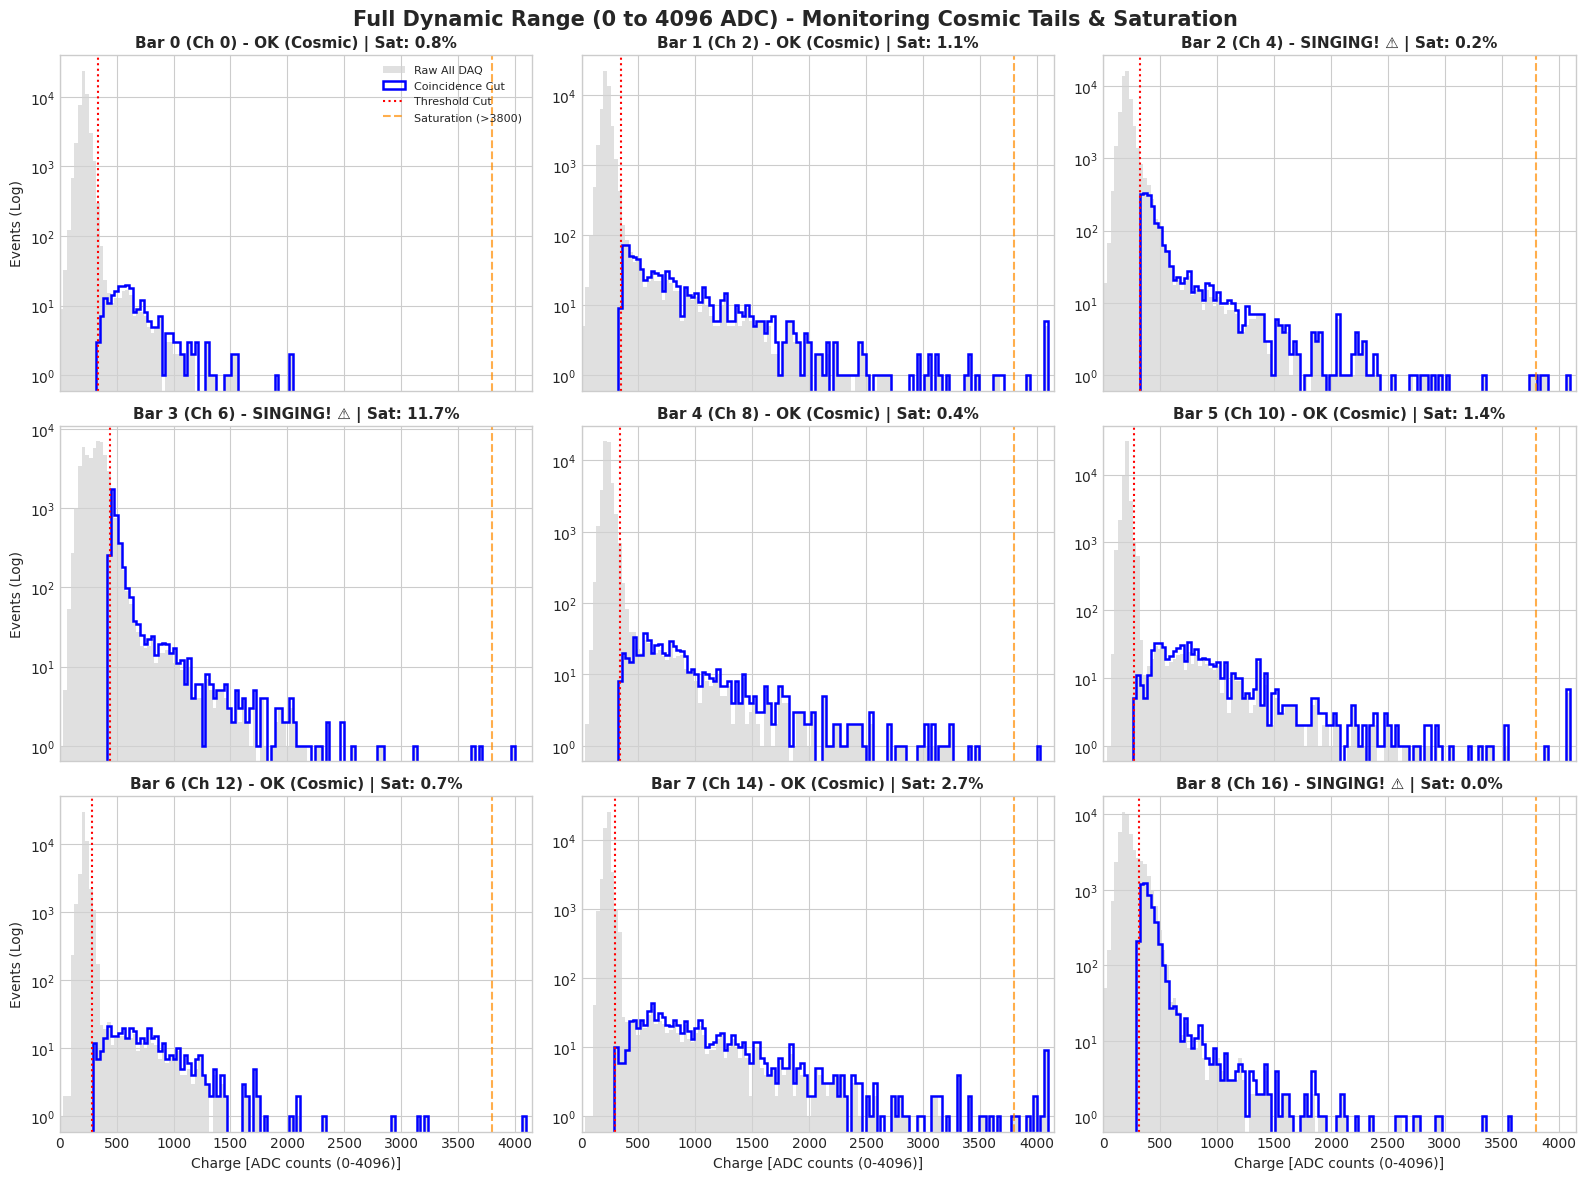

In [11]:
import sys
import numpy as np
import matplotlib.pyplot as plt

try:
    import hdf5plugin
    import h5py
    READER = "h5py"
except ImportError:
    try:
        import tables
        READER = "tables"
    except ImportError:
        print("[-] Please run: pip install hdf5plugin")
        sys.exit(1)

# ==============================================================================
# CONFIGURATION
# ==============================================================================
FILE_PATH = "/lhome/ific/v/villamil/muonveto/NEW_muonveto/data/muons_4.h5"  # <-- Replace with your file name

BAR_MAP = {
    0: (0, 1),
    1: (2, 3),
    2: (4, 5),
    3: (6, 7),
    4: (8, 9),
    5: (10, 11),
    6: (12, 13),
    7: (14, 15),
    8: (16, 17)
}

SATURATION_ADC = 3800  # ADC count threshold considered near saturation/overflow

# ==============================================================================
# DATA LOADING
# ==============================================================================
print(f"Loading data from: {FILE_PATH} ...")
if READER == "h5py":
    with h5py.File(FILE_PATH, 'r') as f:
        charges = np.array(f['charges'])
        events = np.array(f['events'])
else:
    with tables.open_file(FILE_PATH, 'r') as f:
        charges = f.root.charges.read()
        events = f.root.events.read()

n_events, n_channels = charges.shape
timestamps = events['timestamp']
time_diff = timestamps[-1] - timestamps[0]
elapsed_time_s = (time_diff / 1e9) if time_diff > 1e11 else (time_diff / 1000.0 if time_diff > 0 else 1.0)

print(f"Loaded {n_events:,} events over {elapsed_time_s:.2f} seconds.")
print(f"Total DAQ Trigger Rate: {n_events / elapsed_time_s:.1f} Hz\n")

# ==============================================================================
# BASELINE & THRESHOLD DETERMINATION
# ==============================================================================
pedestals = np.zeros(n_channels)
ped_rms = np.zeros(n_channels)
thresholds = np.zeros(n_channels)

for ch in range(n_channels):
    ch_data = charges[:100000, ch]
    counts, bin_edges = np.histogram(ch_data, bins=110, range=(150, 260))
    mode_ped = bin_edges[np.argmax(counts)]
    
    if mode_ped <= 152 or mode_ped >= 258:
        mode_ped = np.median(ch_data)
        
    pedestals[ch] = mode_ped
    mad = np.median(np.abs(ch_data - mode_ped))
    sigma = min(1.4826 * mad, 25.0)
    ped_rms[ch] = max(sigma, 12.0)
    thresholds[ch] = pedestals[ch] + max(5.0 * ped_rms[ch], 50.0)

# ==============================================================================
# COINCIDENCE SEARCH & SATURATION ANALYSIS
# ==============================================================================
bar_stats = {}

print("=" * 110)
print(f"{'Bar':<5} | {'SiPM A/B':<10} | {'Ped A':<10} | {'Ped B':<10} | {'Coinc Hits':<11} | {'Rate (Hz)':<10} | {'Saturated':<10} | {'Status':<12}")
print("=" * 110)

for bar_id, (ch_a, ch_b) in BAR_MAP.items():
    q_a = charges[:, ch_a]
    q_b = charges[:, ch_b]
    
    coincidence_mask = (q_a > thresholds[ch_a]) & (q_b > thresholds[ch_b])
    n_hits = int(np.sum(coincidence_mask))
    rate_hz = n_hits / elapsed_time_s
    
    # Check saturation on coincident hits
    if n_hits > 0:
        sat_hits = np.sum((q_a[coincidence_mask] >= SATURATION_ADC) | (q_b[coincidence_mask] >= SATURATION_ADC))
        sat_pct = (sat_hits / n_hits) * 100.0
    else:
        sat_hits = 0
        sat_pct = 0.0
        
    if rate_hz > 50.0:
        status = "SINGING! ⚠️"
    elif rate_hz < 1.0:
        status = "DEAF / OFF"
    else:
        status = "OK (Cosmic)"
        
    bar_stats[bar_id] = {
        'ch_a': ch_a, 'ch_b': ch_b,
        'hits': n_hits, 'rate': rate_hz,
        'sat_pct': sat_pct,
        'mask': coincidence_mask,
        'q_a': q_a, 'q_b': q_b,
        'status': status
    }
    
    ped_a_str = f"{pedestals[ch_a]:.1f}"
    ped_b_str = f"{pedestals[ch_b]:.1f}"
    print(f"{bar_id:<5} | {ch_a:>2}, {ch_b:<2}   | {ped_a_str:<10} | {ped_b_str:<10} | {n_hits:<11,d} | {rate_hz:<10.1f} | {sat_pct:<9.2f}% | {status:<12}")

print("=" * 110 + "\n")

# ==============================================================================
# FULL DYNAMIC RANGE PLOTTING (0 TO 4096 ADC)
# ==============================================================================
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

fig, axes = plt.subplots(3, 3, figsize=(16, 12), sharex=True)
axes = axes.flatten()

for b in range(9):
    ax = axes[b]
    ch_a = bar_stats[b]['ch_a']
    q_a = bar_stats[b]['q_a']
    coinc_mask = bar_stats[b]['mask']
    
    plot_q = q_a if len(q_a) <= 50000 else np.random.choice(q_a, 50000, replace=False)
    
    # FULL RANGE: 0 to 4096 ADC counts
    ax.hist(plot_q, bins=128, range=(0, 4096), color='lightgray', label='Raw All DAQ', alpha=0.7)
    
    if np.sum(coinc_mask) > 0:
        ax.hist(q_a[coinc_mask], bins=128, range=(0, 4096), color='blue', histtype='step', linewidth=1.8, label='Coincidence Cut')
        
    ax.axvline(thresholds[ch_a], color='red', linestyle=':', label='Threshold Cut')
    ax.axvline(SATURATION_ADC, color='darkorange', linestyle='--', alpha=0.7, label='Saturation (>3800)')
    
    sat_info = f"Sat: {bar_stats[b]['sat_pct']:.1f}%"
    ax.set_title(f"Bar {b} (Ch {ch_a}) - {bar_stats[b]['status']} | {sat_info}", fontsize=11, fontweight='bold')
    ax.set_yscale('log')
    ax.set_xlim(0, 4150)
    
    if b >= 6:
        ax.set_xlabel("Charge [ADC counts (0-4096)]", fontsize=10)
    if b % 3 == 0:
        ax.set_ylabel("Events (Log)", fontsize=10)
    if b == 0:
        ax.legend(fontsize=8, loc='upper right')

plt.suptitle("Full Dynamic Range (0 to 4096 ADC) - Monitoring Cosmic Tails & Saturation", fontsize=15, fontweight='bold')
plt.tight_layout()
#plt.savefig("veto_full_range_4096.png", dpi=200)
print("[+] Saved full range plot: veto_full_range_4096.png")

# Third one

Loading data from: /lhome/ific/v/villamil/muonveto/NEW_muonveto/data/muons_5.h5 ...
Loaded 48,612 events over 57.05 seconds.
Total DAQ Trigger Rate: 852.1 Hz

Bar   | SiPM A/B   | Ped A      | Ped B      | Coinc Hits  | Rate (Hz)  | Saturated  | Status      
0     |  0, 1    | 212.0      | 223.0      | 550         | 9.6        | 2.36     % | OK (Cosmic) 
1     |  2, 3    | 219.0      | 211.0      | 1,821       | 31.9       | 1.37     % | OK (Cosmic) 
2     |  4, 5    | 195.0      | 205.0      | 2,072       | 36.3       | 0.29     % | OK (Cosmic) 
3     |  6, 7    | 203.0      | 205.0      | 13,128      | 230.1      | 11.65    % | SINGING! ⚠️ 
4     |  8, 9    | 225.0      | 198.0      | 1,286       | 22.5       | 1.09     % | OK (Cosmic) 
5     | 10, 11   | 200.0      | 204.0      | 1,430       | 25.1       | 1.40     % | OK (Cosmic) 
6     | 12, 13   | 218.0      | 198.0      | 848         | 14.9       | 0.83     % | OK (Cosmic) 
7     | 14, 15   | 228.0      | 211.0      | 1,618     

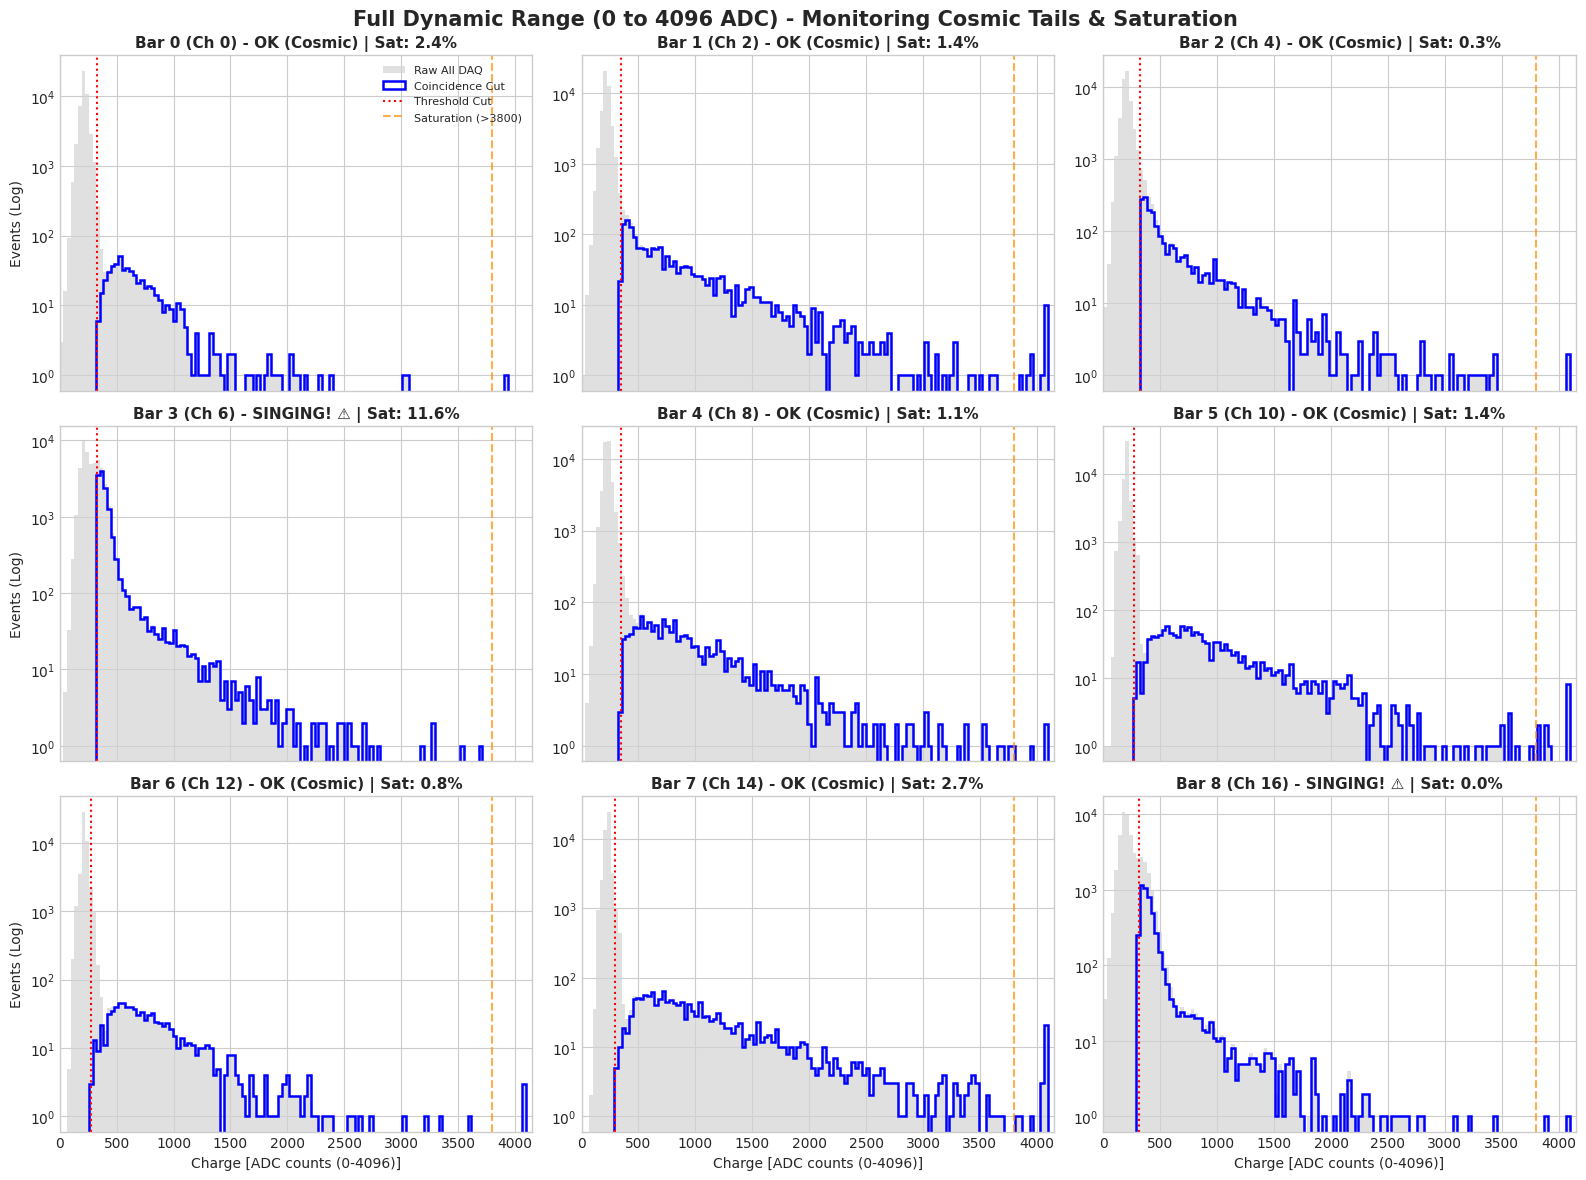

In [12]:
import sys
import numpy as np
import matplotlib.pyplot as plt

try:
    import hdf5plugin
    import h5py
    READER = "h5py"
except ImportError:
    try:
        import tables
        READER = "tables"
    except ImportError:
        print("[-] Please run: pip install hdf5plugin")
        sys.exit(1)

# ==============================================================================
# CONFIGURATION
# ==============================================================================
FILE_PATH = "/lhome/ific/v/villamil/muonveto/NEW_muonveto/data/muons_5.h5"  # <-- Replace with your file name

BAR_MAP = {
    0: (0, 1),
    1: (2, 3),
    2: (4, 5),
    3: (6, 7),
    4: (8, 9),
    5: (10, 11),
    6: (12, 13),
    7: (14, 15),
    8: (16, 17)
}

SATURATION_ADC = 3800  # ADC count threshold considered near saturation/overflow

# ==============================================================================
# DATA LOADING
# ==============================================================================
print(f"Loading data from: {FILE_PATH} ...")
if READER == "h5py":
    with h5py.File(FILE_PATH, 'r') as f:
        charges = np.array(f['charges'])
        events = np.array(f['events'])
else:
    with tables.open_file(FILE_PATH, 'r') as f:
        charges = f.root.charges.read()
        events = f.root.events.read()

n_events, n_channels = charges.shape
timestamps = events['timestamp']
time_diff = timestamps[-1] - timestamps[0]
elapsed_time_s = (time_diff / 1e9) if time_diff > 1e11 else (time_diff / 1000.0 if time_diff > 0 else 1.0)

print(f"Loaded {n_events:,} events over {elapsed_time_s:.2f} seconds.")
print(f"Total DAQ Trigger Rate: {n_events / elapsed_time_s:.1f} Hz\n")

# ==============================================================================
# BASELINE & THRESHOLD DETERMINATION
# ==============================================================================
pedestals = np.zeros(n_channels)
ped_rms = np.zeros(n_channels)
thresholds = np.zeros(n_channels)

for ch in range(n_channels):
    ch_data = charges[:100000, ch]
    counts, bin_edges = np.histogram(ch_data, bins=110, range=(150, 260))
    mode_ped = bin_edges[np.argmax(counts)]
    
    if mode_ped <= 152 or mode_ped >= 258:
        mode_ped = np.median(ch_data)
        
    pedestals[ch] = mode_ped
    mad = np.median(np.abs(ch_data - mode_ped))
    sigma = min(1.4826 * mad, 25.0)
    ped_rms[ch] = max(sigma, 12.0)
    thresholds[ch] = pedestals[ch] + max(5.0 * ped_rms[ch], 50.0)

# ==============================================================================
# COINCIDENCE SEARCH & SATURATION ANALYSIS
# ==============================================================================
bar_stats = {}

print("=" * 110)
print(f"{'Bar':<5} | {'SiPM A/B':<10} | {'Ped A':<10} | {'Ped B':<10} | {'Coinc Hits':<11} | {'Rate (Hz)':<10} | {'Saturated':<10} | {'Status':<12}")
print("=" * 110)

for bar_id, (ch_a, ch_b) in BAR_MAP.items():
    q_a = charges[:, ch_a]
    q_b = charges[:, ch_b]
    
    coincidence_mask = (q_a > thresholds[ch_a]) & (q_b > thresholds[ch_b])
    n_hits = int(np.sum(coincidence_mask))
    rate_hz = n_hits / elapsed_time_s
    
    # Check saturation on coincident hits
    if n_hits > 0:
        sat_hits = np.sum((q_a[coincidence_mask] >= SATURATION_ADC) | (q_b[coincidence_mask] >= SATURATION_ADC))
        sat_pct = (sat_hits / n_hits) * 100.0
    else:
        sat_hits = 0
        sat_pct = 0.0
        
    if rate_hz > 50.0:
        status = "SINGING! ⚠️"
    elif rate_hz < 1.0:
        status = "DEAF / OFF"
    else:
        status = "OK (Cosmic)"
        
    bar_stats[bar_id] = {
        'ch_a': ch_a, 'ch_b': ch_b,
        'hits': n_hits, 'rate': rate_hz,
        'sat_pct': sat_pct,
        'mask': coincidence_mask,
        'q_a': q_a, 'q_b': q_b,
        'status': status
    }
    
    ped_a_str = f"{pedestals[ch_a]:.1f}"
    ped_b_str = f"{pedestals[ch_b]:.1f}"
    print(f"{bar_id:<5} | {ch_a:>2}, {ch_b:<2}   | {ped_a_str:<10} | {ped_b_str:<10} | {n_hits:<11,d} | {rate_hz:<10.1f} | {sat_pct:<9.2f}% | {status:<12}")

print("=" * 110 + "\n")

# ==============================================================================
# FULL DYNAMIC RANGE PLOTTING (0 TO 4096 ADC)
# ==============================================================================
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

fig, axes = plt.subplots(3, 3, figsize=(16, 12), sharex=True)
axes = axes.flatten()

for b in range(9):
    ax = axes[b]
    ch_a = bar_stats[b]['ch_a']
    q_a = bar_stats[b]['q_a']
    coinc_mask = bar_stats[b]['mask']
    
    plot_q = q_a if len(q_a) <= 50000 else np.random.choice(q_a, 50000, replace=False)
    
    # FULL RANGE: 0 to 4096 ADC counts
    ax.hist(plot_q, bins=128, range=(0, 4096), color='lightgray', label='Raw All DAQ', alpha=0.7)
    
    if np.sum(coinc_mask) > 0:
        ax.hist(q_a[coinc_mask], bins=128, range=(0, 4096), color='blue', histtype='step', linewidth=1.8, label='Coincidence Cut')
        
    ax.axvline(thresholds[ch_a], color='red', linestyle=':', label='Threshold Cut')
    ax.axvline(SATURATION_ADC, color='darkorange', linestyle='--', alpha=0.7, label='Saturation (>3800)')
    
    sat_info = f"Sat: {bar_stats[b]['sat_pct']:.1f}%"
    ax.set_title(f"Bar {b} (Ch {ch_a}) - {bar_stats[b]['status']} | {sat_info}", fontsize=11, fontweight='bold')
    ax.set_yscale('log')
    ax.set_xlim(0, 4150)
    
    if b >= 6:
        ax.set_xlabel("Charge [ADC counts (0-4096)]", fontsize=10)
    if b % 3 == 0:
        ax.set_ylabel("Events (Log)", fontsize=10)
    if b == 0:
        ax.legend(fontsize=8, loc='upper right')

plt.suptitle("Full Dynamic Range (0 to 4096 ADC) - Monitoring Cosmic Tails & Saturation", fontsize=15, fontweight='bold')
plt.tight_layout()
#plt.savefig("veto_full_range_4096.png", dpi=200)
print("[+] Saved full range plot: veto_full_range_4096.png")

# Fourth try

Loading data from: /lhome/ific/v/villamil/muonveto/NEW_muonveto/data/muons_6.h5 ...
Loaded 53,825 events over 86.25 seconds.
Total DAQ Trigger Rate: 624.1 Hz

Bar   | SiPM A/B   | Ped A      | Ped B      | Coinc Hits  | Rate (Hz)  | Saturated  | Status      
0     |  0, 1    | 213.0      | 225.0      | 853         | 9.9        | 1.06     % | OK (Cosmic) 
1     |  2, 3    | 219.0      | 208.0      | 2,846       | 33.0       | 0.95     % | OK (Cosmic) 
2     |  4, 5    | 195.0      | 204.0      | 3,097       | 35.9       | 0.45     % | OK (Cosmic) 
3     |  6, 7    | 204.0      | 204.0      | 12,670      | 146.9      | 14.25    % | SINGING! ⚠️ 
4     |  8, 9    | 223.0      | 198.0      | 2,073       | 24.0       | 1.21     % | OK (Cosmic) 
5     | 10, 11   | 203.0      | 205.0      | 2,131       | 24.7       | 1.27     % | OK (Cosmic) 
6     | 12, 13   | 219.0      | 197.0      | 1,205       | 14.0       | 0.41     % | OK (Cosmic) 
7     | 14, 15   | 227.0      | 212.0      | 2,540     

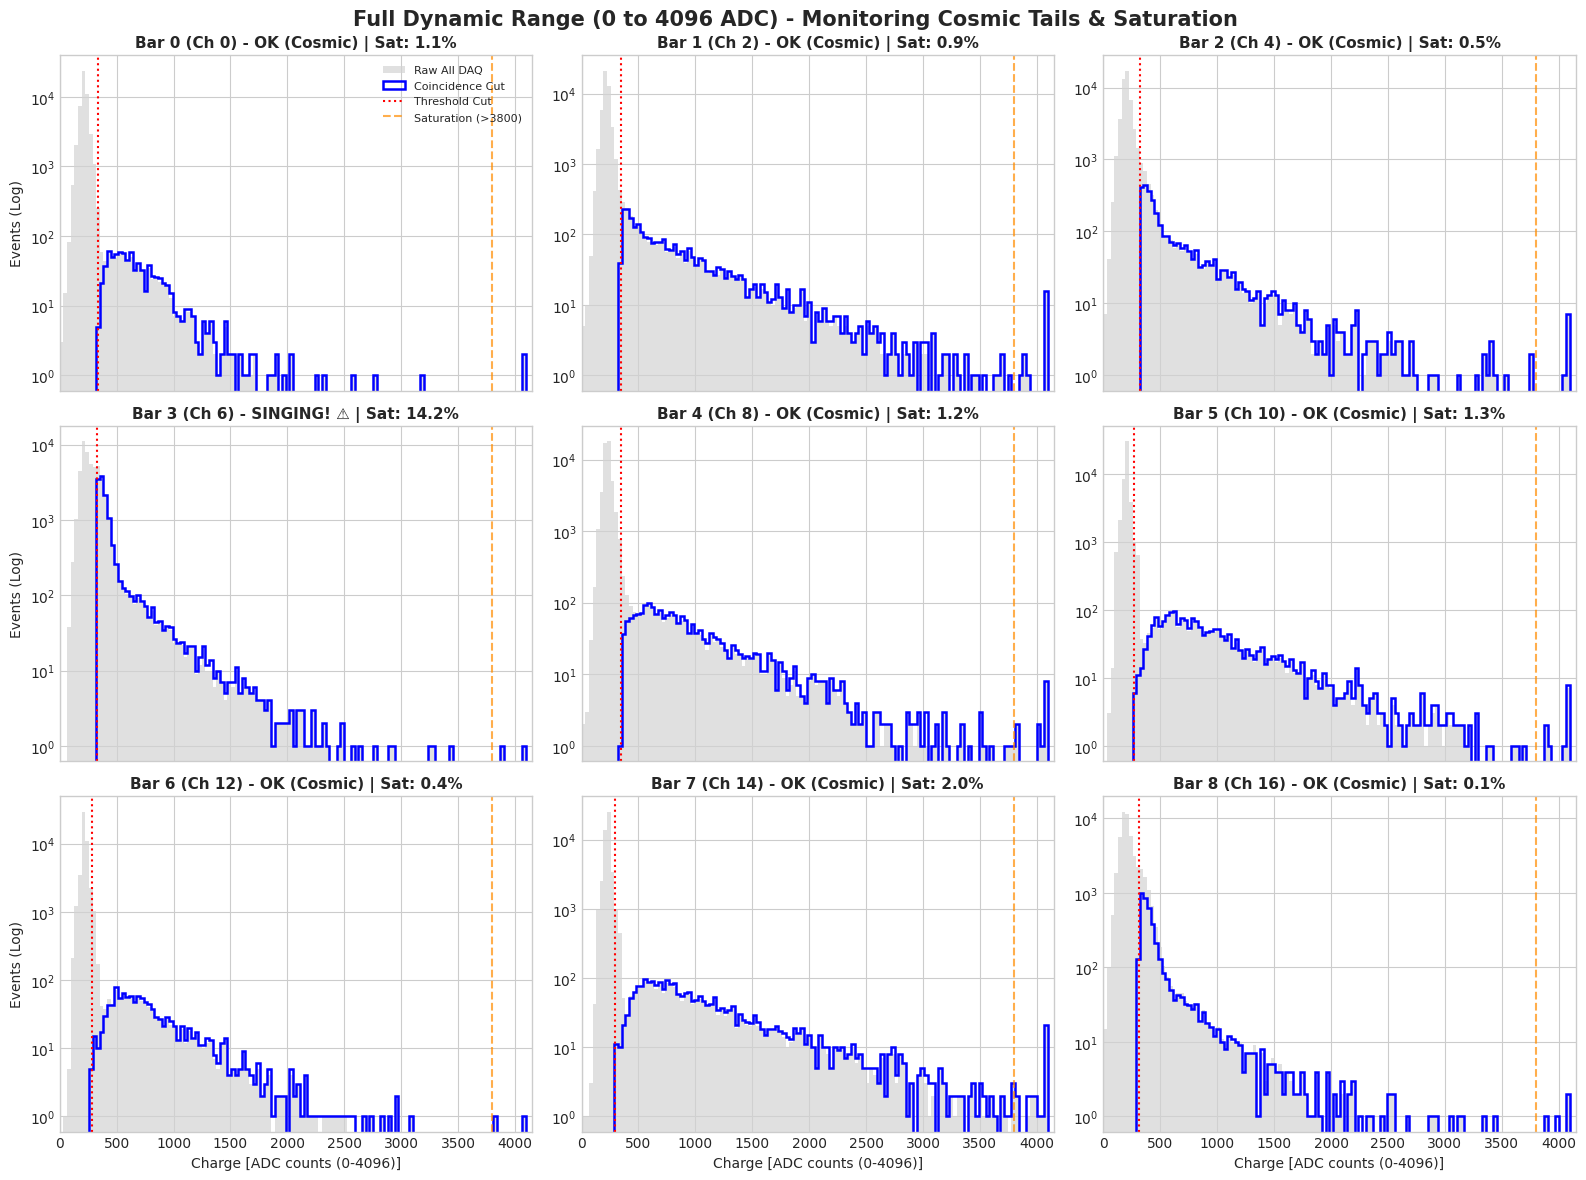

In [15]:
import sys
import numpy as np
import matplotlib.pyplot as plt

try:
    import hdf5plugin
    import h5py
    READER = "h5py"
except ImportError:
    try:
        import tables
        READER = "tables"
    except ImportError:
        print("[-] Please run: pip install hdf5plugin")
        sys.exit(1)

# ==============================================================================
# CONFIGURATION
# ==============================================================================
FILE_PATH = "/lhome/ific/v/villamil/muonveto/NEW_muonveto/data/muons_6.h5"  # <-- Replace with your file name

BAR_MAP = {
    0: (0, 1),
    1: (2, 3),
    2: (4, 5),
    3: (6, 7),
    4: (8, 9),
    5: (10, 11),
    6: (12, 13),
    7: (14, 15),
    8: (16, 17)
}

SATURATION_ADC = 3800  # ADC count threshold considered near saturation/overflow

# ==============================================================================
# DATA LOADING
# ==============================================================================
print(f"Loading data from: {FILE_PATH} ...")
if READER == "h5py":
    with h5py.File(FILE_PATH, 'r') as f:
        charges = np.array(f['charges'])
        events = np.array(f['events'])
else:
    with tables.open_file(FILE_PATH, 'r') as f:
        charges = f.root.charges.read()
        events = f.root.events.read()

n_events, n_channels = charges.shape
timestamps = events['timestamp']
time_diff = timestamps[-1] - timestamps[0]
elapsed_time_s = (time_diff / 1e9) if time_diff > 1e11 else (time_diff / 1000.0 if time_diff > 0 else 1.0)

print(f"Loaded {n_events:,} events over {elapsed_time_s:.2f} seconds.")
print(f"Total DAQ Trigger Rate: {n_events / elapsed_time_s:.1f} Hz\n")

# ==============================================================================
# BASELINE & THRESHOLD DETERMINATION
# ==============================================================================
pedestals = np.zeros(n_channels)
ped_rms = np.zeros(n_channels)
thresholds = np.zeros(n_channels)

for ch in range(n_channels):
    ch_data = charges[:100000, ch]
    counts, bin_edges = np.histogram(ch_data, bins=110, range=(150, 260))
    mode_ped = bin_edges[np.argmax(counts)]
    
    if mode_ped <= 152 or mode_ped >= 258:
        mode_ped = np.median(ch_data)
        
    pedestals[ch] = mode_ped
    mad = np.median(np.abs(ch_data - mode_ped))
    sigma = min(1.4826 * mad, 25.0)
    ped_rms[ch] = max(sigma, 12.0)
    thresholds[ch] = pedestals[ch] + max(5.0 * ped_rms[ch], 50.0)

# ==============================================================================
# COINCIDENCE SEARCH & SATURATION ANALYSIS
# ==============================================================================
bar_stats = {}

print("=" * 110)
print(f"{'Bar':<5} | {'SiPM A/B':<10} | {'Ped A':<10} | {'Ped B':<10} | {'Coinc Hits':<11} | {'Rate (Hz)':<10} | {'Saturated':<10} | {'Status':<12}")
print("=" * 110)

for bar_id, (ch_a, ch_b) in BAR_MAP.items():
    q_a = charges[:, ch_a]
    q_b = charges[:, ch_b]
    
    coincidence_mask = (q_a > thresholds[ch_a]) & (q_b > thresholds[ch_b])
    n_hits = int(np.sum(coincidence_mask))
    rate_hz = n_hits / elapsed_time_s
    
    # Check saturation on coincident hits
    if n_hits > 0:
        sat_hits = np.sum((q_a[coincidence_mask] >= SATURATION_ADC) | (q_b[coincidence_mask] >= SATURATION_ADC))
        sat_pct = (sat_hits / n_hits) * 100.0
    else:
        sat_hits = 0
        sat_pct = 0.0
        
    if rate_hz > 50.0:
        status = "SINGING! ⚠️"
    elif rate_hz < 1.0:
        status = "DEAF / OFF"
    else:
        status = "OK (Cosmic)"
        
    bar_stats[bar_id] = {
        'ch_a': ch_a, 'ch_b': ch_b,
        'hits': n_hits, 'rate': rate_hz,
        'sat_pct': sat_pct,
        'mask': coincidence_mask,
        'q_a': q_a, 'q_b': q_b,
        'status': status
    }
    
    ped_a_str = f"{pedestals[ch_a]:.1f}"
    ped_b_str = f"{pedestals[ch_b]:.1f}"
    print(f"{bar_id:<5} | {ch_a:>2}, {ch_b:<2}   | {ped_a_str:<10} | {ped_b_str:<10} | {n_hits:<11,d} | {rate_hz:<10.1f} | {sat_pct:<9.2f}% | {status:<12}")

print("=" * 110 + "\n")

# ==============================================================================
# FULL DYNAMIC RANGE PLOTTING (0 TO 4096 ADC)
# ==============================================================================
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

fig, axes = plt.subplots(3, 3, figsize=(16, 12), sharex=True)
axes = axes.flatten()

for b in range(9):
    ax = axes[b]
    ch_a = bar_stats[b]['ch_a']
    q_a = bar_stats[b]['q_a']
    coinc_mask = bar_stats[b]['mask']
    
    plot_q = q_a if len(q_a) <= 50000 else np.random.choice(q_a, 50000, replace=False)
    
    # FULL RANGE: 0 to 4096 ADC counts
    ax.hist(plot_q, bins=128, range=(0, 4096), color='lightgray', label='Raw All DAQ', alpha=0.7)
    
    if np.sum(coinc_mask) > 0:
        ax.hist(q_a[coinc_mask], bins=128, range=(0, 4096), color='blue', histtype='step', linewidth=1.8, label='Coincidence Cut')
        
    ax.axvline(thresholds[ch_a], color='red', linestyle=':', label='Threshold Cut')
    ax.axvline(SATURATION_ADC, color='darkorange', linestyle='--', alpha=0.7, label='Saturation (>3800)')
    
    sat_info = f"Sat: {bar_stats[b]['sat_pct']:.1f}%"
    ax.set_title(f"Bar {b} (Ch {ch_a}) - {bar_stats[b]['status']} | {sat_info}", fontsize=11, fontweight='bold')
    ax.set_yscale('log')
    ax.set_xlim(0, 4150)
    
    if b >= 6:
        ax.set_xlabel("Charge [ADC counts (0-4096)]", fontsize=10)
    if b % 3 == 0:
        ax.set_ylabel("Events (Log)", fontsize=10)
    if b == 0:
        ax.legend(fontsize=8, loc='upper right')

plt.suptitle("Full Dynamic Range (0 to 4096 ADC) - Monitoring Cosmic Tails & Saturation", fontsize=15, fontweight='bold')
plt.tight_layout()
#plt.savefig("veto_full_range_4096.png", dpi=200)
print("[+] Saved full range plot: veto_full_range_4096.png")

In [16]:
# Quick check of Bar 3: Ch 6 vs Ch 7
ch6_sat = np.mean(charges[bar_stats[3]['mask'], 6] >= 3800) * 100
ch7_sat = np.mean(charges[bar_stats[3]['mask'], 7] >= 3800) * 100
print(f"Bar 3 Saturation -> Ch 6: {ch6_sat:.2f}% | Ch 7: {ch7_sat:.2f}%")

Bar 3 Saturation -> Ch 6: 0.02% | Ch 7: 14.25%


# Another try


Loading data from: /lhome/ific/v/villamil/muonveto/NEW_muonveto/data/muons_7.h5 ...
Loaded 38,512 events over 78.85 seconds.
Total DAQ Trigger Rate: 488.4 Hz

Bar   | SiPM A,B   | Ped A (RMS)      | Ped B (RMS)      | Sat A %   | Sat B %   | Coinc Hits  | Rate (Hz)  | Status      
0     |  0, 1    | 212.0 (±23.7)    | 223.0 (±13.3)    | 0.00    % | 1.26    % | 794         | 10.1       | OK (Cosmic) 
1     |  2, 3    | 216.0 (±25.0)    | 212.0 (±25.0)    | 0.45    % | 0.23    % | 2,648       | 33.6       | OK (Cosmic) 
2     |  4, 5    | 195.0 (±25.0)    | 203.0 (±25.0)    | 0.38    % | 0.17    % | 2,924       | 37.1       | OK (Cosmic) 
3     |  6, 7    | 203.0 (±25.0)    | 202.0 (±25.0)    | 0.00    % | 19.34   % | 5,310       | 67.3       | SINGING! ⚠️ 
4     |  8, 9    | 219.0 (±25.0)    | 198.0 (±14.8)    | 0.37    % | 1.07    % | 1,874       | 23.8       | OK (Cosmic) 
5     | 10, 11   | 201.0 (±13.3)    | 205.0 (±13.3)    | 0.52    % | 0.94    % | 1,918       | 24.3       | OK (C

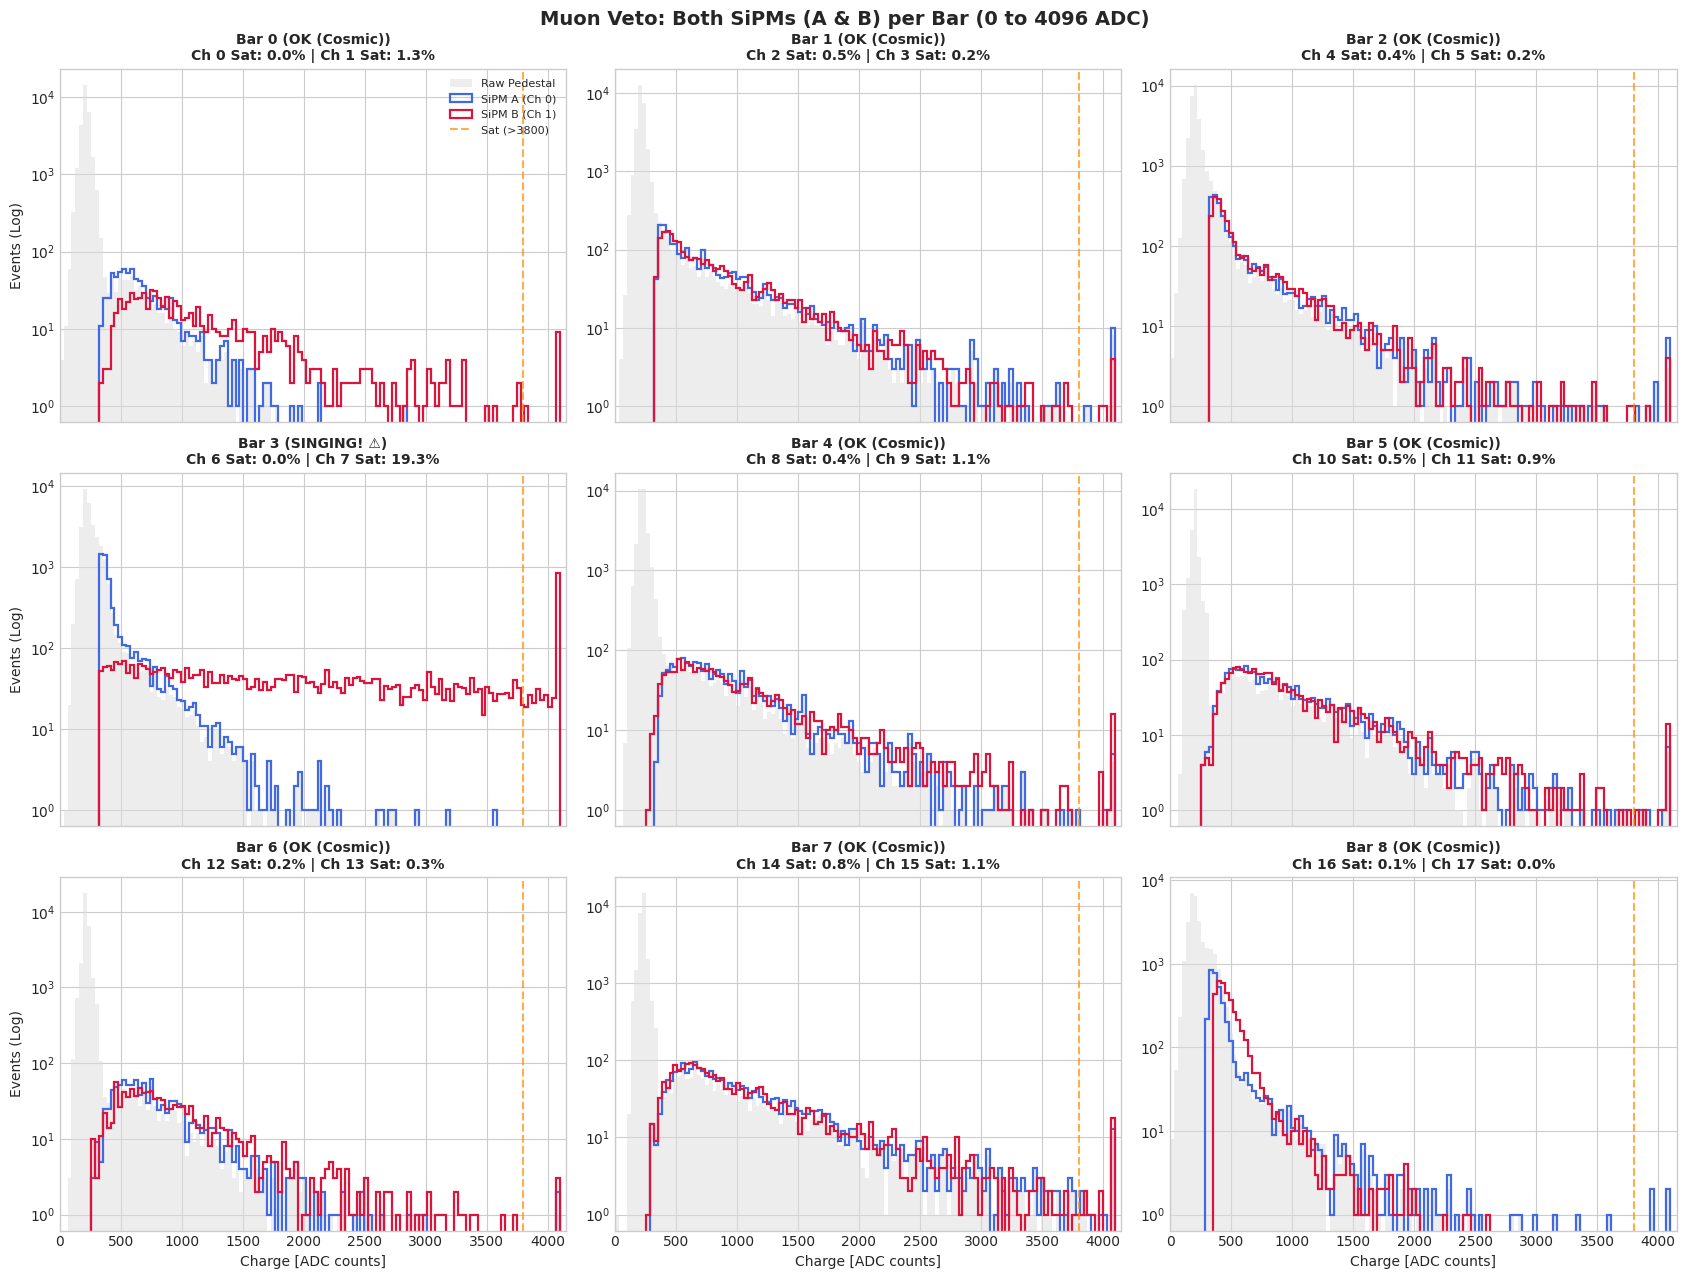

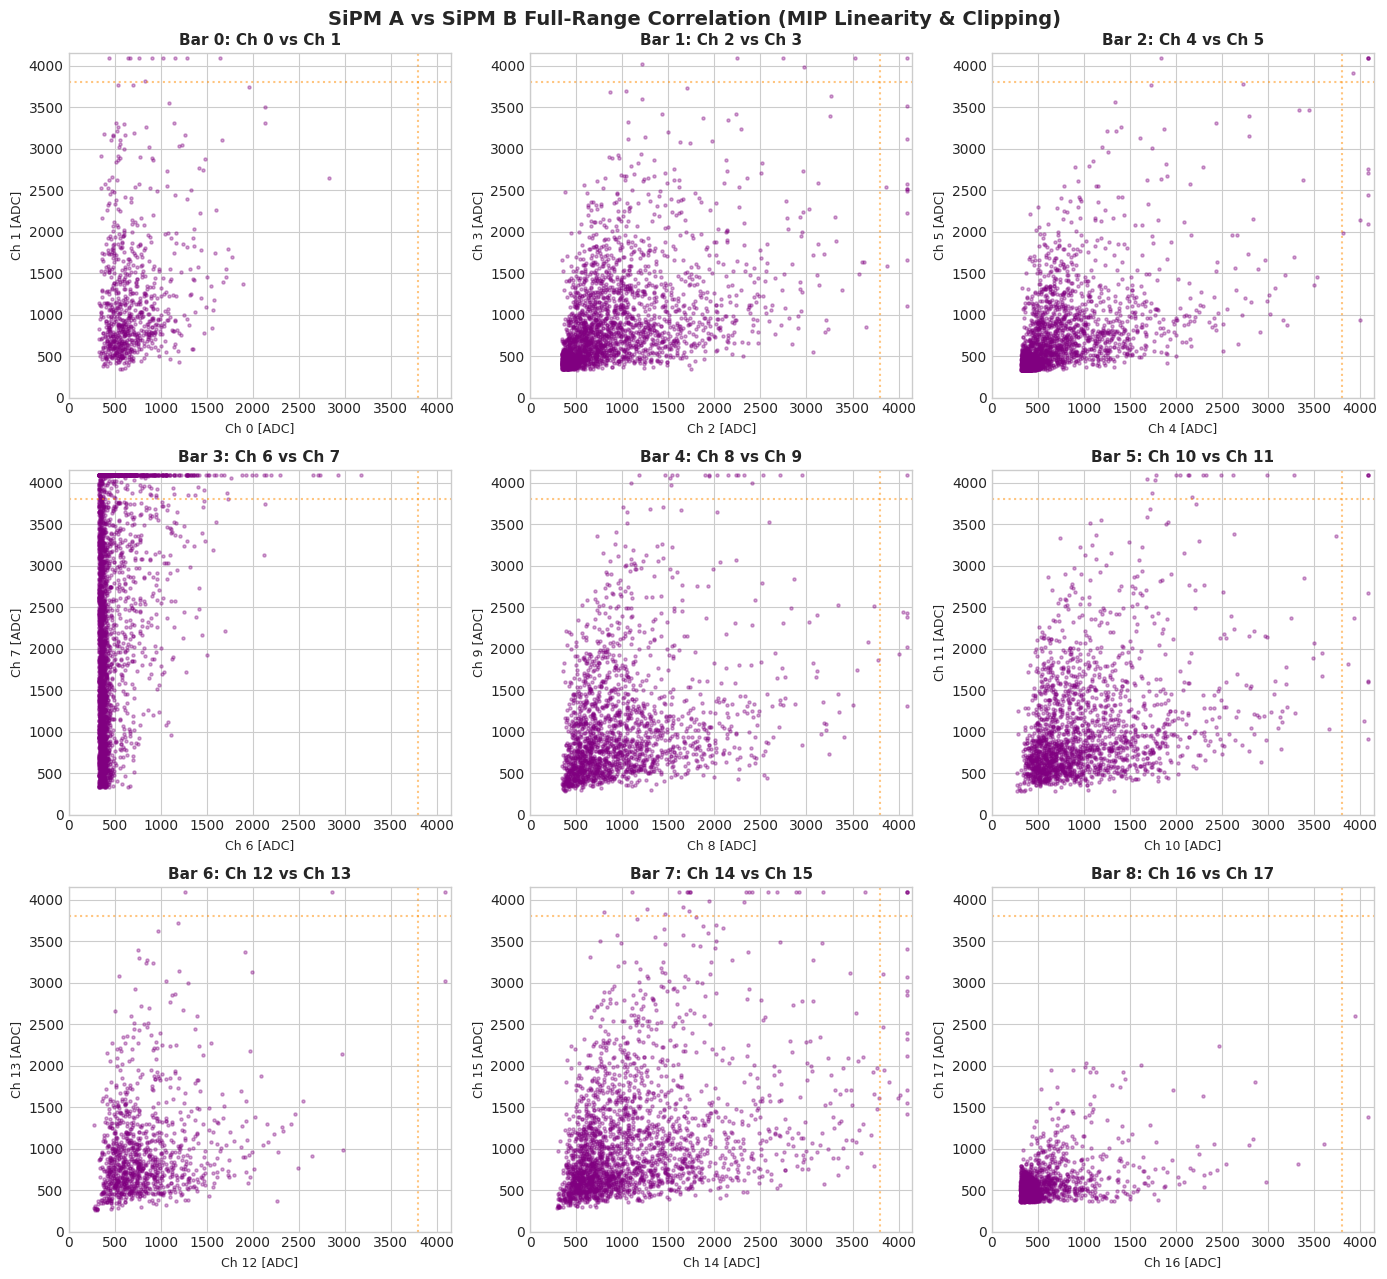

In [19]:
import sys
import numpy as np
import matplotlib.pyplot as plt

try:
    import hdf5plugin
    import h5py
    READER = "h5py"
except ImportError:
    try:
        import tables
        READER = "tables"
    except ImportError:
        print("[-] Please run: pip install hdf5plugin")
        sys.exit(1)

# ==============================================================================
# CONFIGURATION
# ==============================================================================
FILE_PATH = "/lhome/ific/v/villamil/muonveto/NEW_muonveto/data/muons_7.h5"  # <-- Replace with your file name

BAR_MAP = {
    0: (0, 1),
    1: (2, 3),
    2: (4, 5),
    3: (6, 7),
    4: (8, 9),
    5: (10, 11),
    6: (12, 13),
    7: (14, 15),
    8: (16, 17)
}

SATURATION_ADC = 3800  # ADC threshold to flag saturation/overflow

# ==============================================================================
# DATA LOADING
# ==============================================================================
print(f"Loading data from: {FILE_PATH} ...")
if READER == "h5py":
    with h5py.File(FILE_PATH, 'r') as f:
        charges = np.array(f['charges'])
        events = np.array(f['events'])
else:
    with tables.open_file(FILE_PATH, 'r') as f:
        charges = f.root.charges.read()
        events = f.root.events.read()

n_events, n_channels = charges.shape
timestamps = events['timestamp']
time_diff = timestamps[-1] - timestamps[0]
elapsed_time_s = (time_diff / 1e9) if time_diff > 1e11 else (time_diff / 1000.0 if time_diff > 0 else 1.0)

print(f"Loaded {n_events:,} events over {elapsed_time_s:.2f} seconds.")
print(f"Total DAQ Trigger Rate: {n_events / elapsed_time_s:.1f} Hz\n")

# ==============================================================================
# BASELINE & THRESHOLD CALCULATION
# ==============================================================================
pedestals = np.zeros(n_channels)
ped_rms = np.zeros(n_channels)
thresholds = np.zeros(n_channels)

for ch in range(n_channels):
    ch_data = charges[:100000, ch]
    counts, bin_edges = np.histogram(ch_data, bins=110, range=(150, 260))
    mode_ped = bin_edges[np.argmax(counts)]
    
    if mode_ped <= 152 or mode_ped >= 258:
        mode_ped = np.median(ch_data)
        
    pedestals[ch] = mode_ped
    mad = np.median(np.abs(ch_data - mode_ped))
    sigma = min(1.4826 * mad, 25.0)
    ped_rms[ch] = max(sigma, 12.0)
    thresholds[ch] = pedestals[ch] + max(5.0 * ped_rms[ch], 50.0)

# ==============================================================================
# COINCIDENCE SEARCH & INDIVIDUAL CHANNEL METRICS
# ==============================================================================
bar_stats = {}

print("=" * 122)
print(f"{'Bar':<5} | {'SiPM A,B':<10} | {'Ped A (RMS)':<16} | {'Ped B (RMS)':<16} | {'Sat A %':<9} | {'Sat B %':<9} | {'Coinc Hits':<11} | {'Rate (Hz)':<10} | {'Status':<12}")
print("=" * 122)

for bar_id, (ch_a, ch_b) in BAR_MAP.items():
    q_a = charges[:, ch_a]
    q_b = charges[:, ch_b]
    
    # Coincidence condition: Both SiPMs exceed true baseline threshold
    coincidence_mask = (q_a > thresholds[ch_a]) & (q_b > thresholds[ch_b])
    n_hits = int(np.sum(coincidence_mask))
    rate_hz = n_hits / elapsed_time_s
    
    # Individual Saturation Percentages
    if n_hits > 0:
        sat_a_pct = (np.sum(q_a[coincidence_mask] >= SATURATION_ADC) / n_hits) * 100.0
        sat_b_pct = (np.sum(q_b[coincidence_mask] >= SATURATION_ADC) / n_hits) * 100.0
    else:
        sat_a_pct, sat_b_pct = 0.0, 0.0
        
    if rate_hz > 50.0:
        status = "SINGING! ⚠️"
    elif rate_hz < 1.0:
        status = "DEAF / OFF"
    else:
        status = "OK (Cosmic)"
        
    bar_stats[bar_id] = {
        'ch_a': ch_a, 'ch_b': ch_b,
        'hits': n_hits, 'rate': rate_hz,
        'sat_a_pct': sat_a_pct, 'sat_b_pct': sat_b_pct,
        'mask': coincidence_mask,
        'q_a': q_a, 'q_b': q_b,
        'status': status
    }
    
    ped_a_str = f"{pedestals[ch_a]:.1f} (±{ped_rms[ch_a]:.1f})"
    ped_b_str = f"{pedestals[ch_b]:.1f} (±{ped_rms[ch_b]:.1f})"
    print(f"{bar_id:<5} | {ch_a:>2}, {ch_b:<2}   | {ped_a_str:<16} | {ped_b_str:<16} | {sat_a_pct:<8.2f}% | {sat_b_pct:<8.2f}% | {n_hits:<11,d} | {rate_hz:<10.1f} | {status:<12}")

print("=" * 122 + "\n")

# ==============================================================================
# PLOT 1: BOTH SiPMs OVERLAID PER BAR (FULL RANGE 0-4096)
# ==============================================================================
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

fig, axes = plt.subplots(3, 3, figsize=(17, 13), sharex=True)
axes = axes.flatten()

for b in range(9):
    ax = axes[b]
    ch_a = bar_stats[b]['ch_a']
    ch_b = bar_stats[b]['ch_b']
    q_a = bar_stats[b]['q_a']
    q_b = bar_stats[b]['q_b']
    coinc_mask = bar_stats[b]['mask']
    
    # Subsampled raw background for reference
    raw_sub = q_a if len(q_a) <= 30000 else np.random.choice(q_a, 30000, replace=False)
    ax.hist(raw_sub, bins=128, range=(0, 4096), color='gainsboro', label='Raw Pedestal', alpha=0.5)
    
    # Plot BOTH SiPMs in coincidence
    if np.sum(coinc_mask) > 0:
        ax.hist(q_a[coinc_mask], bins=128, range=(0, 4096), color='royalblue', 
                histtype='step', linewidth=1.6, label=f'SiPM A (Ch {ch_a})')
        ax.hist(q_b[coinc_mask], bins=128, range=(0, 4096), color='crimson', 
                histtype='step', linewidth=1.6, label=f'SiPM B (Ch {ch_b})')
        
    ax.axvline(SATURATION_ADC, color='darkorange', linestyle='--', alpha=0.7, label='Sat (>3800)')
    
    title_str = (f"Bar {b} ({bar_stats[b]['status']})\n"
                 f"Ch {ch_a} Sat: {bar_stats[b]['sat_a_pct']:.1f}% | "
                 f"Ch {ch_b} Sat: {bar_stats[b]['sat_b_pct']:.1f}%")
    ax.set_title(title_str, fontsize=10, fontweight='bold')
    ax.set_yscale('log')
    ax.set_xlim(0, 4150)
    
    if b >= 6:
        ax.set_xlabel("Charge [ADC counts]", fontsize=10)
    if b % 3 == 0:
        ax.set_ylabel("Events (Log)", fontsize=10)
    if b == 0:
        ax.legend(fontsize=8, loc='upper right')

plt.suptitle("Muon Veto: Both SiPMs (A & B) per Bar (0 to 4096 ADC)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig("veto_both_sipms_full_range.png", dpi=200)
print("[+] Saved: veto_both_sipms_full_range.png")

# ==============================================================================
# PLOT 2: FULL-RANGE 2D CORRELATION (0 TO 4150 ADC)
# ==============================================================================
fig, axes = plt.subplots(3, 3, figsize=(14, 13))
axes = axes.flatten()

for b in range(9):
    ax = axes[b]
    ch_a = bar_stats[b]['ch_a']
    ch_b = bar_stats[b]['ch_b']
    q_a = bar_stats[b]['q_a']
    q_b = bar_stats[b]['q_b']
    coinc_mask = bar_stats[b]['mask']
    
    if np.sum(coinc_mask) > 5:
        idx = np.where(coinc_mask)[0]
        if len(idx) > 3000:
            idx = np.random.choice(idx, 3000, replace=False)
        ax.scatter(q_a[idx], q_b[idx], color='purple', s=5, alpha=0.35)
    else:
        ax.text(0.5, 0.5, 'No Coincident Hits', ha='center', va='center', transform=ax.transAxes, color='gray')
        
    ax.axhline(SATURATION_ADC, color='darkorange', linestyle=':', alpha=0.5)
    ax.axvline(SATURATION_ADC, color='darkorange', linestyle=':', alpha=0.5)
    ax.set_title(f"Bar {b}: Ch {ch_a} vs Ch {ch_b}", fontsize=11, fontweight='bold')
    ax.set_xlim(0, 4150)
    ax.set_ylim(0, 4150)
    ax.set_xlabel(f"Ch {ch_a} [ADC]", fontsize=9)
    ax.set_ylabel(f"Ch {ch_b} [ADC]", fontsize=9)

plt.suptitle("SiPM A vs SiPM B Full-Range Correlation (MIP Linearity & Clipping)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig("veto_sipm_correlations_full.png", dpi=200)
print("[+] Saved: veto_sipm_correlations_full.png")

print("\nDone! Run this code with your next dataset to inspect both SiPMs side-by-side.")

# Another 

Loading data from: /lhome/ific/v/villamil/muonveto/NEW_muonveto/data/muons_8.h5 ...
Loaded 29,063 events over 59.20 seconds.
Total DAQ Trigger Rate: 490.9 Hz

Bar   | SiPM A,B   | Ped A (RMS)      | Ped B (RMS)      | Sat A %   | Sat B %   | Coinc Hits  | Rate (Hz)  | Status      
0     |  0, 1    | 211.0 (±23.7)    | 223.0 (±13.3)    | 0.00    % | 1.37    % | 584         | 9.9        | OK (Cosmic) 
1     |  2, 3    | 216.0 (±25.0)    | 217.0 (±25.0)    | 0.70    % | 0.70    % | 2,006       | 33.9       | OK (Cosmic) 
2     |  4, 5    | 196.0 (±25.0)    | 202.0 (±25.0)    | 0.05    % | 0.14    % | 2,118       | 35.8       | OK (Cosmic) 
3     |  6, 7    | 210.0 (±25.0)    | 207.0 (±25.0)    | 0.03    % | 20.68   % | 3,545       | 59.9       | SINGING! ⚠️ 
4     |  8, 9    | 220.0 (±25.0)    | 199.0 (±14.8)    | 0.76    % | 0.55    % | 1,449       | 24.5       | OK (Cosmic) 
5     | 10, 11   | 202.0 (±13.3)    | 205.0 (±13.3)    | 0.84    % | 0.77    % | 1,429       | 24.1       | OK (C

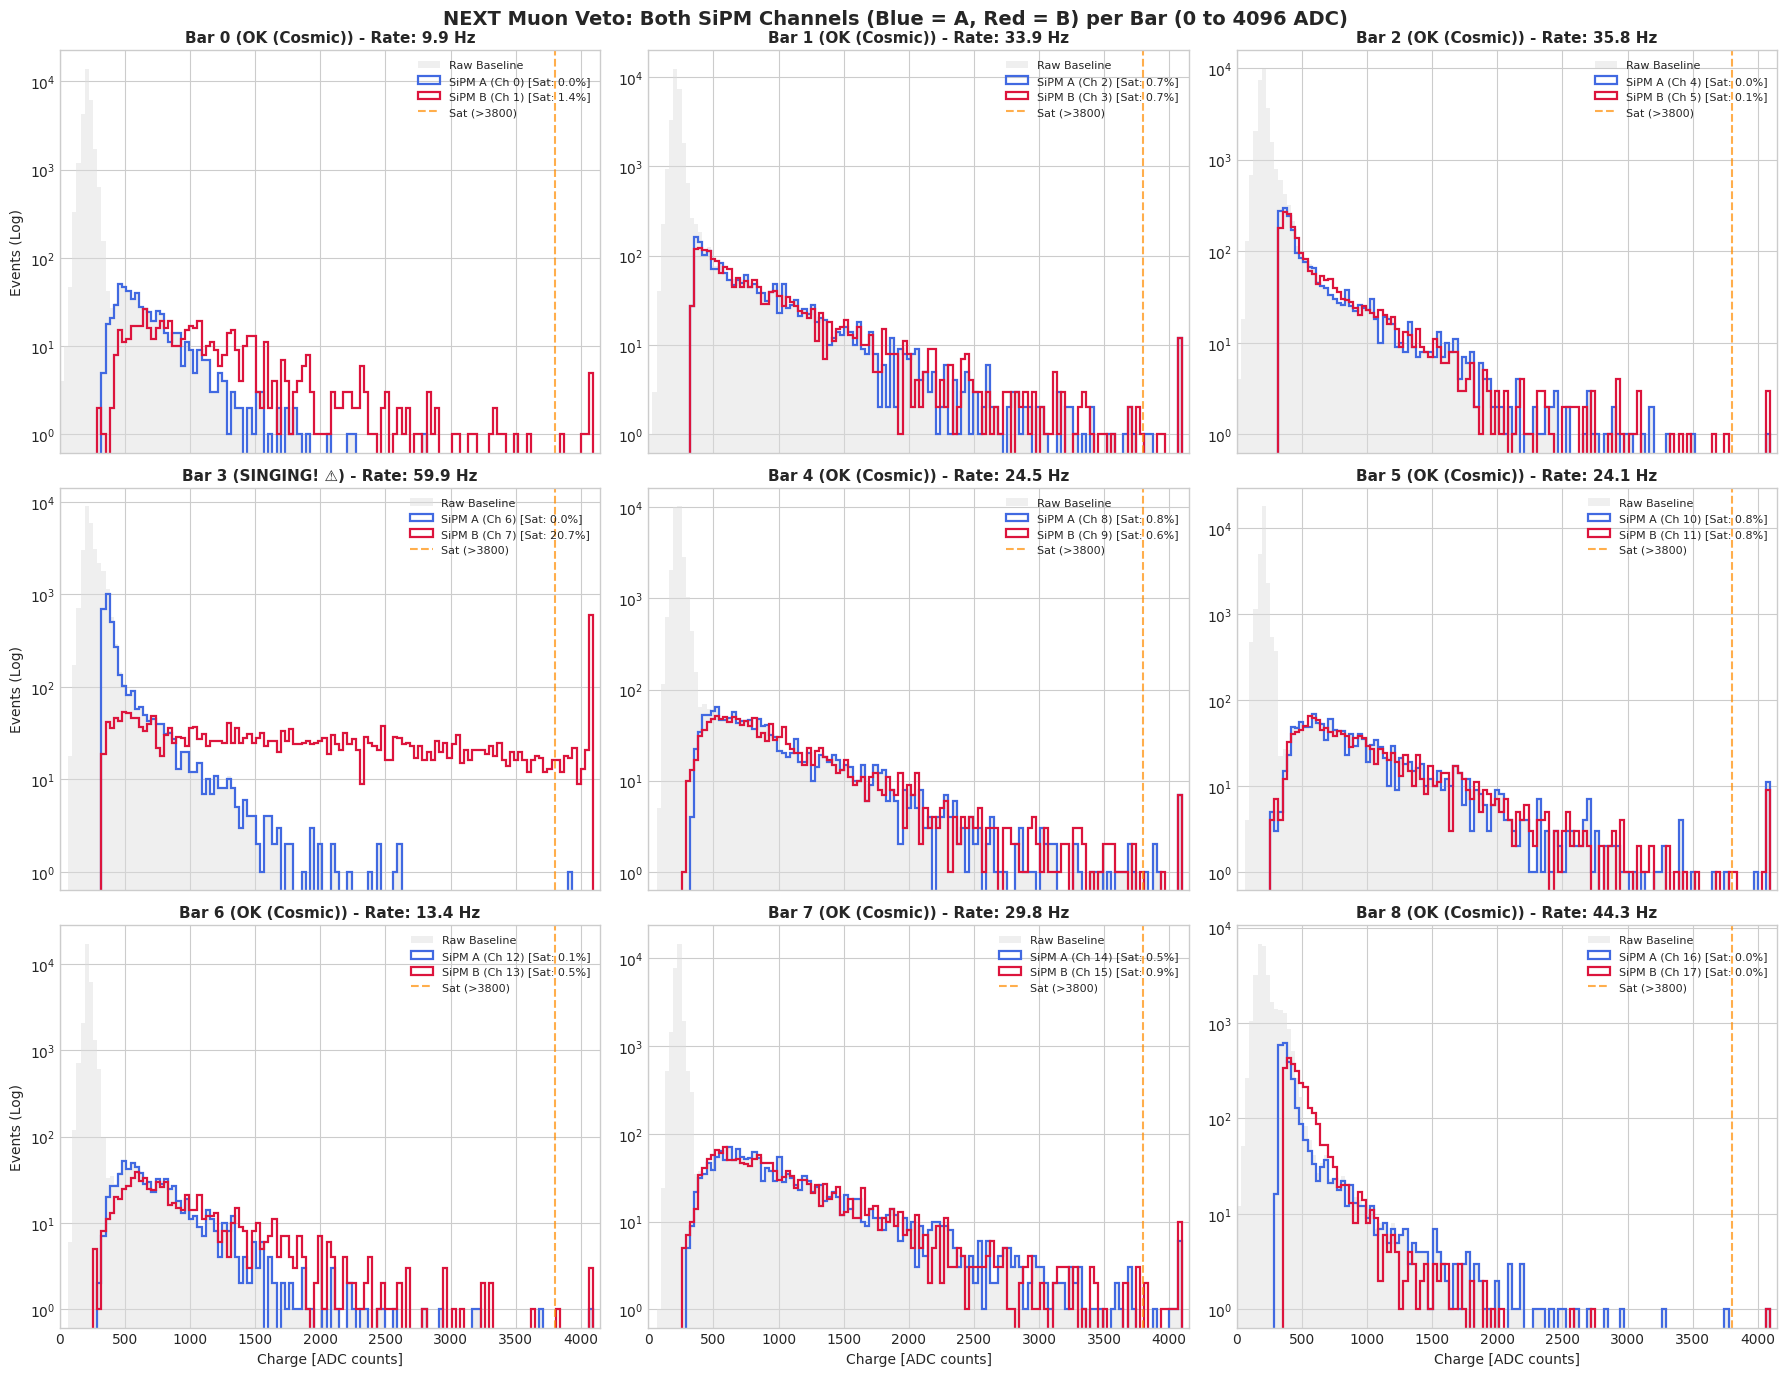

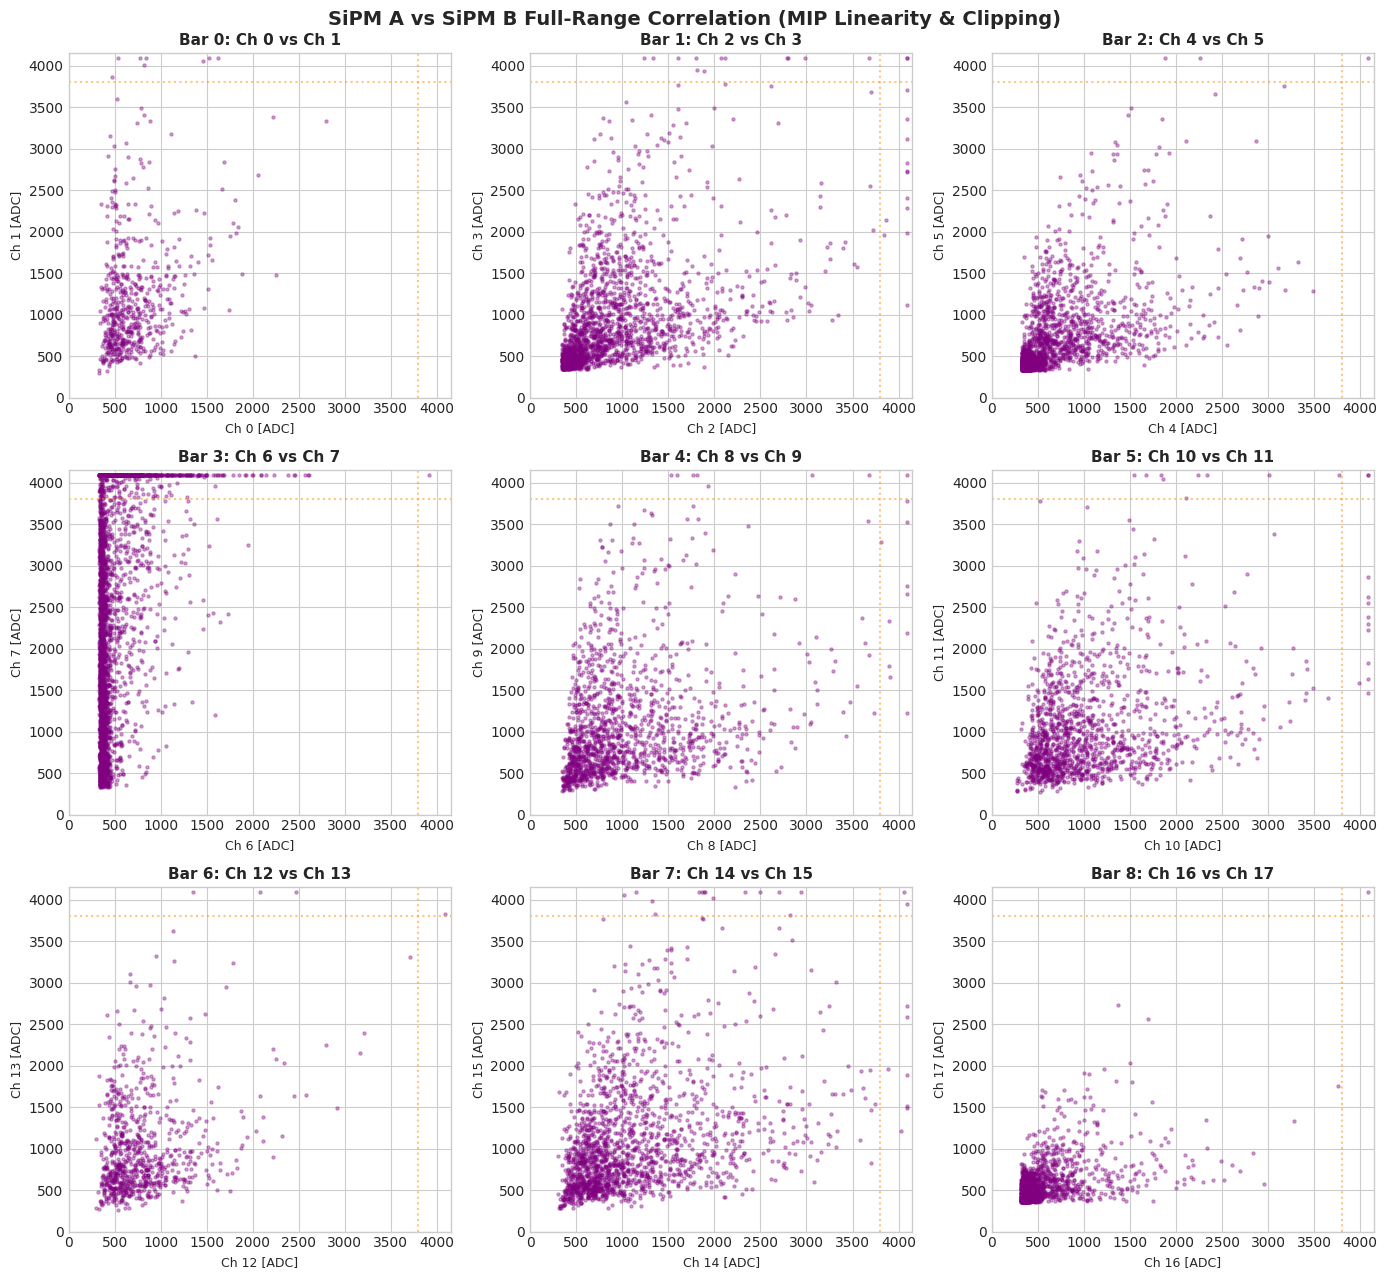

In [1]:
import sys
import numpy as np
import matplotlib.pyplot as plt

try:
    import hdf5plugin
    import h5py
    READER = "h5py"
except ImportError:
    try:
        import tables
        READER = "tables"
    except ImportError:
        print("[-] Please run: pip install hdf5plugin")
        sys.exit(1)

# ==============================================================================
# CONFIGURATION
# ==============================================================================
FILE_PATH = "/lhome/ific/v/villamil/muonveto/NEW_muonveto/data/muons_8.h5"  # <-- Replace with your file name

BAR_MAP = {
    0: (0, 1),
    1: (2, 3),
    2: (4, 5),
    3: (6, 7),
    4: (8, 9),
    5: (10, 11),
    6: (12, 13),
    7: (14, 15),
    8: (16, 17)
}

SATURATION_ADC = 3800  # ADC count threshold for saturation

# ==============================================================================
# DATA LOADING
# ==============================================================================
print(f"Loading data from: {FILE_PATH} ...")
if READER == "h5py":
    with h5py.File(FILE_PATH, 'r') as f:
        charges = np.array(f['charges'])
        events = np.array(f['events'])
else:
    with tables.open_file(FILE_PATH, 'r') as f:
        charges = f.root.charges.read()
        events = f.root.events.read()

n_events, n_channels = charges.shape
timestamps = events['timestamp']
time_diff = timestamps[-1] - timestamps[0]
elapsed_time_s = (time_diff / 1e9) if time_diff > 1e11 else (time_diff / 1000.0 if time_diff > 0 else 1.0)

print(f"Loaded {n_events:,} events over {elapsed_time_s:.2f} seconds.")
print(f"Total DAQ Trigger Rate: {n_events / elapsed_time_s:.1f} Hz\n")

# ==============================================================================
# BASELINE & THRESHOLD DETERMINATION
# ==============================================================================
pedestals = np.zeros(n_channels)
ped_rms = np.zeros(n_channels)
thresholds = np.zeros(n_channels)

for ch in range(n_channels):
    ch_data = charges[:100000, ch]
    counts, bin_edges = np.histogram(ch_data, bins=110, range=(150, 260))
    mode_ped = bin_edges[np.argmax(counts)]
    
    if mode_ped <= 152 or mode_ped >= 258:
        mode_ped = np.median(ch_data)
        
    pedestals[ch] = mode_ped
    mad = np.median(np.abs(ch_data - mode_ped))
    sigma = min(1.4826 * mad, 25.0)
    ped_rms[ch] = max(sigma, 12.0)
    thresholds[ch] = pedestals[ch] + max(5.0 * ped_rms[ch], 50.0)

# ==============================================================================
# COINCIDENCE SEARCH & INDIVIDUAL METRICS
# ==============================================================================
bar_stats = {}

print("=" * 122)
print(f"{'Bar':<5} | {'SiPM A,B':<10} | {'Ped A (RMS)':<16} | {'Ped B (RMS)':<16} | {'Sat A %':<9} | {'Sat B %':<9} | {'Coinc Hits':<11} | {'Rate (Hz)':<10} | {'Status':<12}")
print("=" * 122)

for bar_id, (ch_a, ch_b) in BAR_MAP.items():
    q_a = charges[:, ch_a]
    q_b = charges[:, ch_b]
    
    coincidence_mask = (q_a > thresholds[ch_a]) & (q_b > thresholds[ch_b])
    n_hits = int(np.sum(coincidence_mask))
    rate_hz = n_hits / elapsed_time_s
    
    if n_hits > 0:
        sat_a_pct = (np.sum(q_a[coincidence_mask] >= SATURATION_ADC) / n_hits) * 100.0
        sat_b_pct = (np.sum(q_b[coincidence_mask] >= SATURATION_ADC) / n_hits) * 100.0
    else:
        sat_a_pct, sat_b_pct = 0.0, 0.0
        
    if rate_hz > 50.0:
        status = "SINGING! ⚠️"
    elif rate_hz < 1.0:
        status = "DEAF / OFF"
    else:
        status = "OK (Cosmic)"
        
    bar_stats[bar_id] = {
        'ch_a': ch_a, 'ch_b': ch_b,
        'hits': n_hits, 'rate': rate_hz,
        'sat_a_pct': sat_a_pct, 'sat_b_pct': sat_b_pct,
        'mask': coincidence_mask,
        'q_a': q_a, 'q_b': q_b,
        'status': status
    }
    
    ped_a_str = f"{pedestals[ch_a]:.1f} (±{ped_rms[ch_a]:.1f})"
    ped_b_str = f"{pedestals[ch_b]:.1f} (±{ped_rms[ch_b]:.1f})"
    print(f"{bar_id:<5} | {ch_a:>2}, {ch_b:<2}   | {ped_a_str:<16} | {ped_b_str:<16} | {sat_a_pct:<8.2f}% | {sat_b_pct:<8.2f}% | {n_hits:<11,d} | {rate_hz:<10.1f} | {status:<12}")

print("=" * 122 + "\n")

# ==============================================================================
# PLOTTING: ALL BARS WITH INDIVIDUAL LEGENDS
# ==============================================================================
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

fig, axes = plt.subplots(3, 3, figsize=(18, 14), sharex=True)
axes = axes.flatten()

for b in range(9):
    ax = axes[b]
    ch_a = bar_stats[b]['ch_a']
    ch_b = bar_stats[b]['ch_b']
    q_a = bar_stats[b]['q_a']
    q_b = bar_stats[b]['q_b']
    coinc_mask = bar_stats[b]['mask']
    
    # Subsampled raw baseline for comparison
    raw_sub = q_a if len(q_a) <= 30000 else np.random.choice(q_a, 30000, replace=False)
    ax.hist(raw_sub, bins=128, range=(0, 4096), color='gainsboro', label='Raw Baseline', alpha=0.45)
    
    # Overlay both SiPMs
    if np.sum(coinc_mask) > 0:
        ax.hist(q_a[coinc_mask], bins=128, range=(0, 4096), color='royalblue', 
                histtype='step', linewidth=1.6, label=f'SiPM A (Ch {ch_a}) [Sat: {bar_stats[b]["sat_a_pct"]:.1f}%]')
        ax.hist(q_b[coinc_mask], bins=128, range=(0, 4096), color='crimson', 
                histtype='step', linewidth=1.6, label=f'SiPM B (Ch {ch_b}) [Sat: {bar_stats[b]["sat_b_pct"]:.1f}%]')
        
    ax.axvline(SATURATION_ADC, color='darkorange', linestyle='--', alpha=0.7, label='Sat (>3800)')
    
    ax.set_title(f"Bar {b} ({bar_stats[b]['status']}) - Rate: {bar_stats[b]['rate']:.1f} Hz", fontsize=11, fontweight='bold')
    ax.set_yscale('log')
    ax.set_xlim(0, 4150)
    
    # Explicit legend on EVERY subplot
    ax.legend(fontsize=8, loc='upper right', framealpha=0.9)
    
    if b >= 6:
        ax.set_xlabel("Charge [ADC counts]", fontsize=10)
    if b % 3 == 0:
        ax.set_ylabel("Events (Log)", fontsize=10)

plt.suptitle("NEXT Muon Veto: Both SiPM Channels (Blue = A, Red = B) per Bar (0 to 4096 ADC)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig("veto_both_sipms_with_legends.png", dpi=200)
print("[+] Saved: veto_both_sipms_with_legends.png")


# ==============================================================================
# PLOT 2: FULL-RANGE 2D CORRELATION (0 TO 4150 ADC)
# ==============================================================================
fig, axes = plt.subplots(3, 3, figsize=(14, 13))
axes = axes.flatten()

for b in range(9):
    ax = axes[b]
    ch_a = bar_stats[b]['ch_a']
    ch_b = bar_stats[b]['ch_b']
    q_a = bar_stats[b]['q_a']
    q_b = bar_stats[b]['q_b']
    coinc_mask = bar_stats[b]['mask']
    
    if np.sum(coinc_mask) > 5:
        idx = np.where(coinc_mask)[0]
        if len(idx) > 3000:
            idx = np.random.choice(idx, 3000, replace=False)
        ax.scatter(q_a[idx], q_b[idx], color='purple', s=5, alpha=0.35)
    else:
        ax.text(0.5, 0.5, 'No Coincident Hits', ha='center', va='center', transform=ax.transAxes, color='gray')
        
    ax.axhline(SATURATION_ADC, color='darkorange', linestyle=':', alpha=0.5)
    ax.axvline(SATURATION_ADC, color='darkorange', linestyle=':', alpha=0.5)
    ax.set_title(f"Bar {b}: Ch {ch_a} vs Ch {ch_b}", fontsize=11, fontweight='bold')
    ax.set_xlim(0, 4150)
    ax.set_ylim(0, 4150)
    ax.set_xlabel(f"Ch {ch_a} [ADC]", fontsize=9)
    ax.set_ylabel(f"Ch {ch_b} [ADC]", fontsize=9)

plt.suptitle("SiPM A vs SiPM B Full-Range Correlation (MIP Linearity & Clipping)", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig("veto_sipm_correlations_full.png", dpi=200)
print("[+] Saved: veto_sipm_correlations_full.png")